# Proyecto final · Olist: del pedido a la reseña

**Equipo:** [Apellido Nombre] y [Apellido Nombre]

Esta plantilla solo fija **el orden y los encabezados** (no los borres: se usan para calificar). El código y las decisiones son de ustedes. Pueden agregar todas las celdas que necesiten dentro de cada parte.

Antes de entregar: *Entorno de ejecución › Reiniciar y ejecutar todo*. El notebook debe correr de principio a fin sin errores.

## 0. Conexión

Usen el usuario de solo lectura del curso. Los datos están en el esquema `final`.

In [1]:
!pip install -q sqlalchemy "psycopg[binary]"

In [2]:
import warnings
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from sqlalchemy.pool import NullPool
from sqlalchemy import text
warnings.filterwarnings("ignore")

HOST = "aws-0-us-west-2.pooler.supabase.com"
PORT = 6543
DATABASE = "postgres"
USERNAME = "alumnos_lectura.ashlmfqpqutuoqtcmzqp"

password = getpass("Contraseña de la base de datos: ")

url = URL.create(
    drivername="postgresql+psycopg",
    username=USERNAME,
    password=password,
    host=HOST,
    port=PORT,
    database=DATABASE,
)

motor = create_engine(url, poolclass=NullPool)
pd.read_sql("SELECT table_name FROM information_schema.tables WHERE table_schema = 'final' ORDER BY 1", motor)

Contraseña de la base de datos: ··········


,table_name
0,category_translation
1,customers
2,order_items
3,order_payments
4,order_reviews
5,orders
6,products
7,sellers


## Parte 1 · Datos

Escriban la consulta SQL que produce **una fila por pedido entregado y con reseña** con las 18 columnas del contrato (ver enunciado, sección "Contrato"). Expliquen en Markdown cada decisión: qué hicieron con pedidos de varios artículos, varios pagos y varias reseñas.

In [4]:
query = text("""
WITH estado AS (
  SELECT
    o.order_id,
    s.seller_state,
    p.product_category_name
  FROM final.orders o
  LEFT JOIN final.order_items oi ON oi.order_id = o.order_id
  LEFT JOIN final.sellers s ON s.seller_id = oi.seller_id
  LEFT JOIN final.products p ON p.product_id = oi.product_id
  WHERE o.order_status = 'delivered' AND oi.order_item_id = 1
),
items AS (
  SELECT
    order_id,
    COUNT(order_item_id) AS n_items,
    COUNT(DISTINCT seller_id) AS n_vendedores,
    SUM(price) AS precio_total,
    SUM(freight_value) AS flete_total
  FROM final.order_items
  GROUP BY order_id
),
productos AS (
  SELECT
    oi.order_id,
    SUM(p.product_weight_g) AS peso_total_g,
    AVG(p.product_photos_qty) AS fotos_promedio
  FROM final.order_items oi
  LEFT JOIN final.products p ON p.product_id = oi.product_id
  GROUP BY oi.order_id
),
pagos AS (
  SELECT
    order_id,
    payment_type,
    payment_value,
    MAX(payment_installments) OVER (PARTITION BY order_id) AS cuotas_max,
    ROW_NUMBER() OVER (
      PARTITION BY order_id
      ORDER BY payment_value DESC, payment_sequential
    ) AS rn
  FROM final.order_payments
),
resenas AS (
  SELECT
    order_id,
    review_score,
    ROW_NUMBER() OVER (
      PARTITION BY order_id
      ORDER BY review_answer_timestamp DESC, review_id
    ) AS rn
  FROM final.order_reviews
),
tabla AS (
  SELECT
    o.order_id,
    o.order_purchase_timestamp,
    o.order_approved_at,
    o.order_delivered_carrier_date,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    c.customer_state AS estado_cliente,
    i.n_items,
    i.n_vendedores,
    i.precio_total,
    i.flete_total,
    pr.peso_total_g,
    pr.fotos_promedio,
    e.product_category_name AS categoria,
    e.seller_state AS estado_vendedor,
    pa.payment_type AS tipo_pago,
    pa.cuotas_max,
    CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END AS mala_resena
  FROM final.orders o
  JOIN final.customers c ON c.customer_id = o.customer_id
  JOIN  estado e ON e.order_id = o.order_id
  JOIN  items i ON i.order_id = o.order_id
  JOIN  productos pr ON pr.order_id = o.order_id
  LEFT JOIN  pagos pa ON pa.order_id = o.order_id AND pa.rn = 1
  JOIN resenas r ON r.order_id = o.order_id AND r.rn = 1
  WHERE o.order_status = 'delivered'  AND o.order_delivered_customer_date IS NOT NULL
  AND TRIM(o.order_delivered_customer_date::text) <> ''
  AND o.order_delivered_customer_date <> '0001-01-01 00:00:00'
  AND o.order_purchase_timestamp< '2018-06-01'

)
SELECT * FROM tabla
""")

with motor.connect() as connection:
    pedidos = pd.read_sql_query(query, connection)

# Verificación: una sola fila por pedido
pedidos["order_id"].is_unique, pedidos.shape

(True, (77304, 18))

Explicación de decisiones
Utilice with como indicaban las instruciones, dado que si utilizaba las tablas directamente en el join se iban a multiplicar las filas por orden_id porque existen por ejemplo varios sellers o items asosciados a una orden. Así que cree 6 subtablas dentro de mi consulta:
1. En la primera mapeo el estado de los vendedores dejando el seller con item número 1. De esta tabla extraigo el estado y la categoría.
2. De la tabla order_items realize un group nby para traer la cantidad de sellers, el precio, el flete y  la cantidad de items de una orden.
3. De la tabla de productos por order_id creo las métricas para la suma del peso de la orden y las fotos.
4. De la tabla de pagos realizo un order by partition porque quiero por orden_id ordenar de acuerdo al pago más alto y extraer su método de pago.
5. De la tabla de reviews realizo un case para categorizar con 1 las malas reseñas.
6. Finalmente a la tabla de orders le realizo un join a cada una de las tablas creadas anteriomente ya que me intereza mapear la información de las ordenes comunes entre las tablas.
Por último realizó un select a mi tabla final y así obtengo los 77,304 registros y las 18 columnas del contrato.

Esta celda verifica el contrato. Debe imprimir `True`:

In [5]:
CONTRATO = ["order_id", "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_estimated_delivery_date", "estado_cliente", "n_items",
            "n_vendedores", "precio_total", "flete_total", "peso_total_g", "fotos_promedio", "categoria",
            "estado_vendedor", "tipo_pago", "cuotas_max", "mala_resena"]
print("Contrato completo:", list(pedidos.columns) == CONTRATO, "|", len(pedidos), "pedidos")

Contrato completo: True | 77304 pedidos


In [6]:
#Este es un lote de prueba que utilizaré para testear la API
import json
import pandas as pd
from google.colab import files

cols = CONTRATO[:-1]
datos = pedidos[cols].copy()
fechas = [c for c in cols if c.startswith("order_") and c != "order_id"]
for c in fechas:
    datos[c] = pd.to_datetime(datos[c], errors="coerce")
for c in ["n_items", "n_vendedores"]:
    datos[c] = pd.to_numeric(datos[c], errors="coerce")

retraso = (datos["order_delivered_customer_date"].dt.normalize()
           - datos["order_estimated_delivery_date"].dt.normalize()).dt.days   # positivo = tarde

simple = (datos["n_items"] == 1) & (datos["n_vendedores"] == 1)
grupos = {
    "entrega a tiempo":     simple & (retraso <= 0),
    "retraso +8 días":      simple & (retraso >= 8),
    "dos vendedores":       (datos["n_vendedores"] == 2) & (retraso <= 0),
    "tres o más artículos": (datos["n_items"] >= 3) & (datos["n_vendedores"] == 1) & (retraso <= 0),
}

def a_registros(df):
    d = df.copy()
    for c in fechas:
        d[c] = d[c].dt.strftime("%Y-%m-%dT%H:%M:%S")
    return json.loads(d.to_json(orient="records"))

ejemplos = []
for etiqueta, m in grupos.items():
    if m.any():
        reg = a_registros(datos[m].sample(1, random_state=7))[0]
        reg["etiqueta"] = etiqueta
        ejemplos.append(reg)

with open("ejemplos.json", "w", encoding="utf-8") as f:
    json.dump(ejemplos, f, ensure_ascii=False, indent=2)
with open("lote_prueba.json", "w", encoding="utf-8") as f:
    json.dump(a_registros(datos.sample(200, random_state=1)), f, ensure_ascii=False, indent=2)

files.download("ejemplos.json")
files.download("lote_prueba.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Limpieza y diccionario de variables

Faltantes, valores raros y qué hicieron con ellos. Tabla con cada variable que crean en `preparacion.py`: nombre, cómo se calcula y qué significa.

In [ ]:
#Mapear nulls
pedidos.isna().sum()

,0
order_id,0
order_purchase_timestamp,0
order_approved_at,14
order_delivered_carrier_date,1
order_delivered_customer_date,0
order_estimated_delivery_date,0
estado_cliente,0
n_items,0
n_vendedores,0
precio_total,0


In [ ]:
pedidos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77304 entries, 0 to 77303
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       77304 non-null  object        
 1   order_purchase_timestamp       77304 non-null  datetime64[ns]
 2   order_approved_at              77290 non-null  datetime64[ns]
 3   order_delivered_carrier_date   77303 non-null  datetime64[ns]
 4   order_delivered_customer_date  77304 non-null  datetime64[ns]
 5   order_estimated_delivery_date  77304 non-null  datetime64[ns]
 6   estado_cliente                 77304 non-null  object        
 7   n_items                        77304 non-null  int64         
 8   n_vendedores                   77304 non-null  int64         
 9   precio_total                   77304 non-null  float64       
 10  flete_total                    77304 non-null  float64       
 11  peso_total_g   

In [ ]:
%%writefile preparacion.py
#%%writefile -a preparacion.py

import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

def validar_fechas_pedido(df, medianas=None):
    """
    1) Convierte las fechas a datetime64[ns] (lo no convertible queda NaT).
    2) Calcula la mediana (en horas) entre fechas consecutivas, solo con pares válidos.
    3) Imputa solo los nulls: fecha previa + mediana.
       Si esa fecha supera a la fecha siguiente (válida), usa la fecha previa.
    Devuelve el mismo DataFrame, con las mismas columnas.
    medianas: dict {columna: horas}. Si es None, se calculan con df.
    """
    d = df.copy()
    orden = [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
    ]
    col_estimada = "order_estimated_delivery_date"

    # 1. Tipos
    for c in orden + [col_estimada]:
        s = pd.to_datetime(d[c], errors="coerce")
        if s.dt.tz is not None:
            s = s.dt.tz_localize(None)
        d[c] = s.astype("datetime64[ns]")

    # 2. Medianas en horas (solo pares con ambas fechas y en orden)
    if medianas is None:
        medianas = {}
        for ant, post in zip(orden[:-1], orden[1:]):
            ok = d[ant].notna() & d[post].notna() & (d[post] >= d[ant])
            horas = (d.loc[ok, post] - d.loc[ok, ant]).dt.total_seconds() / 3600
            medianas[post] = horas.median()

    # 3. Imputación en cascada, solo nulls
    original = d[orden].copy()          # fecha siguiente tal como venía

    for i in range(1, len(orden)):
        ant, col = orden[i - 1], orden[i]
        prev = d[ant]                   # ya con las imputaciones anteriores

        imputable = d[col].isna() & prev.notna()
        candidata = prev + pd.to_timedelta(medianas[col], unit="h")

        if i + 1 < len(orden):
            sig = original[orden[i + 1]]
            excede = sig.notna() & (sig >= prev) & (candidata > sig)
            candidata = candidata.where(~excede, prev)

        d.loc[imputable, col] = candidata[imputable]

    d.attrs["medianas"] = medianas      #Sirve para guardarlas, ya que las utlizaresmos
    return d

def convertir_tipos(X):
    """
    Convierte los tipos de datos de las columnas de interés y devuelve
    el DataFrame completo (las demás columnas quedan intactas).
    """

    numericas   = ['precio_total', 'flete_total', 'fotos_promedio']
    enteras     = ['n_items', 'n_vendedores', 'cuotas_max']
    categoricas = ['order_id', 'estado_cliente', 'categoria',
                   'estado_vendedor', 'tipo_pago']
    mayus = ['estado_cliente', 'estado_vendedor']
    minus = ['tipo_pago', 'categoria']

    # Validaciones previas
    todas = [*numericas, *enteras, *categoricas]

    repetidas = sorted({c for c in todas if todas.count(c) > 1})
    if repetidas:
        raise ValueError(f"Columnas en más de un grupo: {repetidas}")

    faltantes = [c for c in todas if c not in X.columns]
    if faltantes:
        raise KeyError(f"Columnas que no existen en el DataFrame: {faltantes}")

    # Conversión
    def a_numero(serie):
        # Si ya es numérica no se pasa por texto (evita dañar valores como 1e-05)
        if pd.api.types.is_numeric_dtype(serie):
            return serie.astype('float64')
        limpio = (serie.astype('string').str.strip()
                       .str.replace(',', '.', regex=False)
                       .str.replace(r'[^0-9.\-]', '', regex=True)
                       .replace('', pd.NA))
        return pd.to_numeric(limpio, errors='coerce').astype('float64')

    copia = X.copy()

    for c in numericas:
        copia[c] = a_numero(copia[c])

    for c in enteras:
        serie = a_numero(copia[c])
        copia[c] = serie.where(serie % 1 == 0).astype('Int64')

    for c in categoricas:
        serie = (copia[c].astype('string').str.strip()
                         .str.replace(r'\s+', ' ', regex=True)
                         .replace('', pd.NA))
        if c in mayus:
            serie = serie.str.upper()
        elif c in minus:
            serie = serie.str.lower()
        copia[c] = serie

    return copia

def validar_rangos(X):
    """
    Deja en null los valores que incumplen reglas de negocio.
    Devuelve el DataFrame completo. Debe ir después de convertir_tipos.
    """
    uf_validas = {"AC","AL","AP","AM","BA","CE","DF","ES","GO","MA","MT","MS","MG",
                  "PA","PB","PR","PE","PI","RJ","RN","RS","RO","RR","SC","SP","SE","TO"}

    copia = X.copy()

    for c in ['precio_total', 'flete_total', 'cuotas_max']:
        copia[c] = copia[c].mask(copia[c] < 0)

    copia['n_items'] = copia['n_items'].mask(copia['n_items'] < 1)

    for c in ['estado_cliente', 'estado_vendedor']:
        copia[c] = copia[c].where(copia[c].isin(uf_validas))

    return copia

def crear_variables(X):
    """
    Crea variables derivadas para el modelo de mala_resena.
    Recibe el DataFrame completo y lo devuelve con las columnas nuevas.
    """
    d = X.copy()

    # 1. Mismo estado cliente / vendedor (0/1)
    sin_estado = d['estado_cliente'].isna() | d['estado_vendedor'].isna()
    d['mismo_estado'] = ((d['estado_cliente'] == d['estado_vendedor'])
                         .astype('Int64').mask(sin_estado))

    # 2. Cumplimiento de la entrega (el día como referencia)
    # dif > 0: llegó antes de lo prometido | dif = 0: el mismo día | dif < 0: llegó tarde
    dif = (d['order_estimated_delivery_date'].dt.normalize()
           - d['order_delivered_customer_date'].dt.normalize()).dt.days

    d['dias_dif_entrega'] = dif.astype('Int64')            # estimada - real
    d['dias_retraso']     = (-dif).clip(lower=0).astype('Int64')
    d['dias_adelanto']    = dif.clip(lower=0).astype('Int64')
    d['estado_entrega'] = (
        pd.Series(np.select([dif == 0, dif < 0, dif > 0],
                            ['a_tiempo', 'tardia', 'adelantada'], default=''),
                  index=d.index)
        .replace('', pd.NA).astype('string')
    )
    d['entrega_tardia'] = (dif < 0).astype('Int64').mask(dif.isna())

    # 3. Flete vs. precio
    precio = d['precio_total']
    flete = d['flete_total']
    sin_monto = precio.isna() | flete.isna()
    d['flete_mayor_precio'] = (flete > precio).astype('Int64').mask(sin_monto)
    d['pct_flete'] = (100 * flete / precio.where(precio > 0)).round(2)

    #  4. Horas entre compra y aprobación del pago
    d['horas_aprobacion'] = (
        (d['order_approved_at'] - d['order_purchase_timestamp'])
        .dt.total_seconds() / 3600
    )

    # 5. Variables de Tiempo
    # Tiempos del proceso
    d['dias_entrega_total'] = (
        (d['order_delivered_customer_date'] - d['order_purchase_timestamp'])
        .dt.total_seconds() / 86400
    )
    d['dias_prometidos'] = (
        (d['order_estimated_delivery_date'] - d['order_purchase_timestamp'])
        .dt.total_seconds() / 86400
    )
    d['ratio_entrega'] = d['dias_entrega_total'] / d['dias_prometidos'].where(d['dias_prometidos'] > 0)
    d['dias_despacho'] = (
        (d['order_delivered_carrier_date'] - d['order_approved_at'])
        .dt.total_seconds() / 86400
    )
    d['dias_transito'] = (
        (d['order_delivered_customer_date'] - d['order_delivered_carrier_date'])
        .dt.total_seconds() / 86400
    )

    # Valor por ítem
    items = d['n_items'].astype('float64').where(d['n_items'] > 0)
    d['precio_por_item'] = precio / items
    d['flete_por_item']  = flete / items

    # Complejidad del pedido y del pago
    d['multi_vendedor'] = (d['n_vendedores'] > 1).astype('Int64').mask(d['n_vendedores'].isna())
    d['pago_en_cuotas'] = (d['cuotas_max'] > 1).astype('Int64').mask(d['cuotas_max'].isna())

    # Calendario de la compra
    d['hora_compra'] = d['order_purchase_timestamp'].dt.hour.astype('Int64')
    d['dia_semana_compra'] = d['order_purchase_timestamp'].dt.dayofweek.astype('Int64')   # 0 = lunes
    d['compra_fin_semana'] = (d['dia_semana_compra'] >= 5).astype('Int64')

    return d

#Realizo esta selección de variables que ocuparé para entrenar mi modelo
NUMERICAS = ['n_items', 'n_vendedores', 'precio_total', 'flete_total', 'peso_total_g',
             'fotos_promedio', 'cuotas_max', 'pct_flete', 'horas_aprobacion',
             'dias_entrega_total', 'dias_prometidos', 'ratio_entrega', 'dias_despacho',
             'dias_transito', 'dias_dif_entrega', 'precio_por_item', 'flete_por_item',
             'hora_compra', 'dia_semana_compra']
BINARIAS  = ['mismo_estado', 'flete_mayor_precio', 'multi_vendedor',
             'pago_en_cuotas', 'compra_fin_semana']
NOMINALES = ['estado_cliente', 'estado_vendedor', 'categoria', 'tipo_pago']


def seleccionar_variables(X):
    """Deja solo las variables del modelo, con tipos que scikit-learn lee bien (NaN, no pd.NA)."""
    d = X[NUMERICAS + BINARIAS + NOMINALES].copy()
    for c in NUMERICAS + BINARIAS:
        d[c] = pd.to_numeric(d[c], errors='coerce').astype('float64')
    for c in NOMINALES:
        s = d[c].astype('object')
        d[c] = s.where(s.notna(), np.nan)
    return d


def crear_pipeline(medianas=None):
    return Pipeline([
        ("fechas",    FunctionTransformer(validar_fechas_pedido, kw_args={"medianas": medianas})),
        ("tipos",     FunctionTransformer(convertir_tipos)),
        ("rangos",    FunctionTransformer(validar_rangos)),
        ("variables", FunctionTransformer(crear_variables)),
    ])

Writing preparacion.py


In [ ]:
import os
print(os.path.exists("preparacion.py"), os.getcwd())

True /content


In [ ]:
#Valido que pueda realizar la transformación y cálculo de variables con mi archivo preparación
import sys, importlib
sys.modules.pop("preparacion", None)
importlib.invalidate_caches()

import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from preparacion import (validar_fechas_pedido, convertir_tipos,
                         validar_rangos, crear_variables)

pipe = Pipeline([
    ("fechas",    FunctionTransformer(validar_fechas_pedido)),
    ("tipos",     FunctionTransformer(convertir_tipos)),
    ("rangos",    FunctionTransformer(validar_rangos)),
    ("variables", FunctionTransformer(crear_variables)),
])

df_final = pipe.fit_transform(pedidos)

# Verificaciones
assert len(df_final) == len(pedidos), "Cambió la cantidad de filas"
assert df_final.index.equals(pedidos.index), "Cambió el índice"
assert set(pedidos.columns) <= set(df_final.columns), "Se perdieron columnas originales"

nuevas = [c for c in df_final.columns if c not in pedidos.columns]
print("Columnas originales:", pedidos.shape[1], "| nuevas:", len(nuevas))
print(nuevas)

fechas = ["order_purchase_timestamp", "order_approved_at",
          "order_delivered_carrier_date", "order_delivered_customer_date",
          "order_estimated_delivery_date"]
print(df_final[fechas].dtypes)
print(df_final[fechas].isna().sum())     # approved y carrier deberían quedar en 0

print(df_final[nuevas].dtypes)
print(df_final[nuevas].isna().sum())

Columnas originales: 18 | nuevas: 21
['mismo_estado', 'dias_dif_entrega', 'dias_retraso', 'dias_adelanto', 'estado_entrega', 'entrega_tardia', 'flete_mayor_precio', 'pct_flete', 'horas_aprobacion', 'dias_entrega_total', 'dias_prometidos', 'ratio_entrega', 'dias_despacho', 'dias_transito', 'precio_por_item', 'flete_por_item', 'multi_vendedor', 'pago_en_cuotas', 'hora_compra', 'dia_semana_compra', 'compra_fin_semana']
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64
mismo_estado                   Int64
dias_dif_entrega               Int64
dias_retraso                   Int64
dias_adelanto              

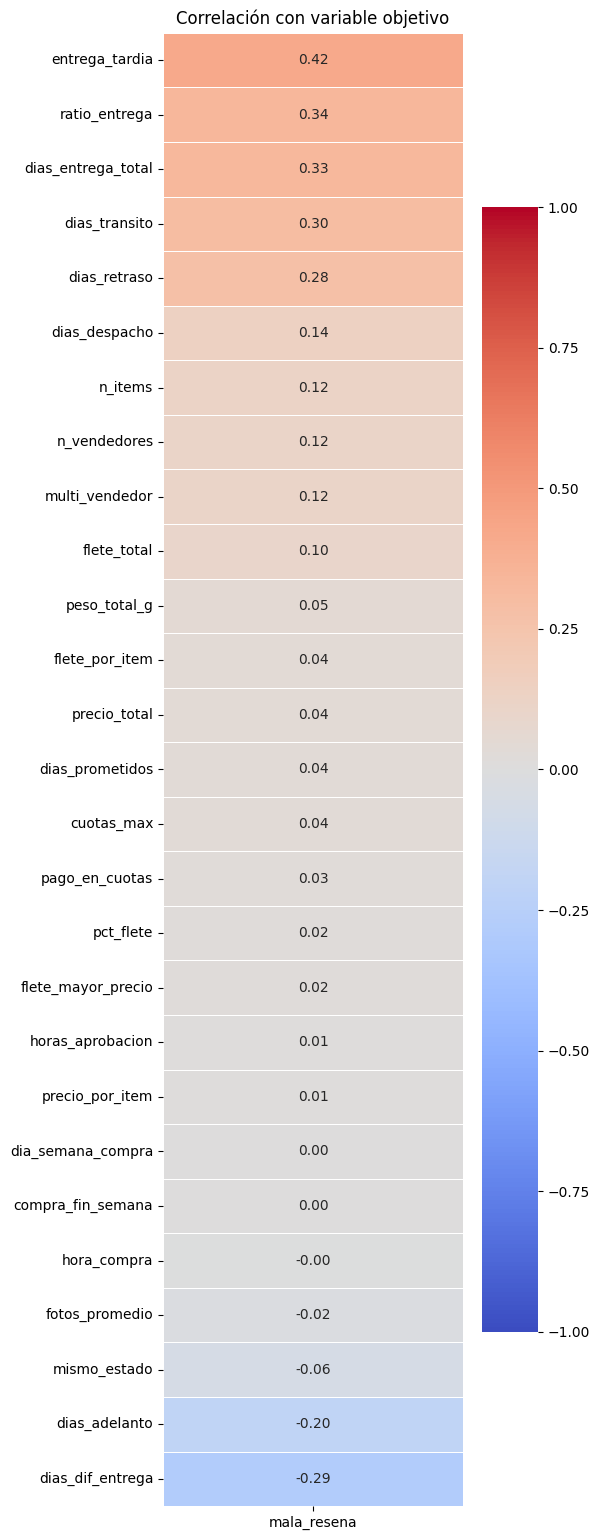

In [ ]:
#Correlaciones para validar mi selección previa
import seaborn as sns
corr_objetivo = (
    df_final.corr(numeric_only=True)[['mala_resena']]
    .drop('mala_resena')
    .sort_values(by='mala_resena', ascending=False)
)

plt.figure(figsize=(6, 0.5 * len(corr_objetivo) + 2))
sns.heatmap(
    corr_objetivo,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title('Correlación con variable objetivo')
plt.tight_layout()
plt.show()


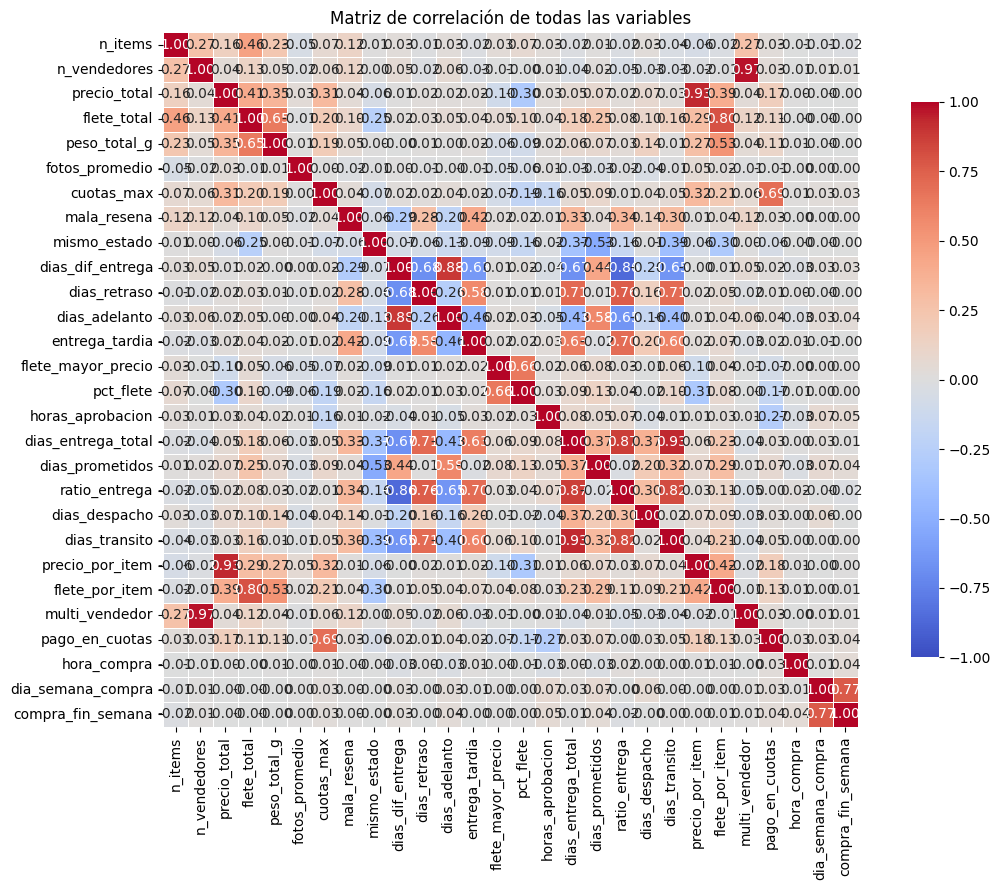

In [ ]:
corr = df_final.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={'shrink': 0.8}
)
plt.title('Matriz de correlación de todas las variables')
plt.tight_layout()
plt.show()

## Parte 2 · Modelo de riesgo

Recuerden:

- La validación es **por fecha**.
- Comparen contra la regla "ordenar por días de retraso" usando **precisión en el 10% de mayor riesgo**.
- Las funciones que transforman las columnas del contrato van en `preparacion.py` y se importan aquí.

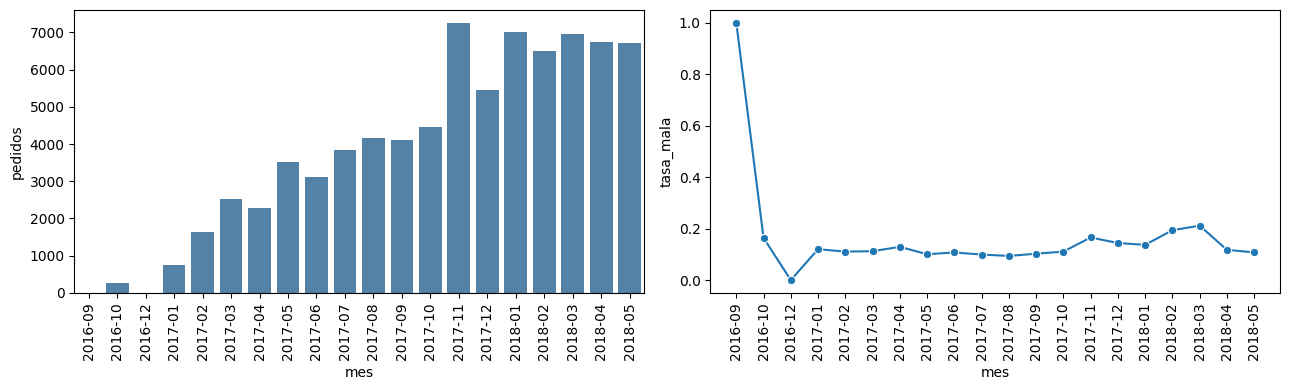

corte: 2018-02-28 | train: 56580 | val: 20724
tasa mala reseña  train: 0.1308 | val: 0.148
{'azar': np.float64(0.14799266550858908), 'regla_retraso': np.float64(0.6332046332046332)}
azar                      0.1480
regla_retraso             0.6332
regresion_logistica       0.6530
xgboost                   0.6800
random_forest             0.6757
hist_gradient_boosting    0.6776
Name: precision_top10, dtype: float64


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from preparacion import (validar_fechas_pedido, crear_pipeline, seleccionar_variables,
                         NUMERICAS, BINARIAS, NOMINALES)

# Objetivo limpio y fecha de referencia
final = pedidos.copy()
final["mala_resena"] = pd.to_numeric(final["mala_resena"], errors="coerce")
final = final[final["mala_resena"].isin([0, 1])]
fecha = pd.to_datetime(final["order_purchase_timestamp"], errors="coerce")

X = final.drop(columns="mala_resena")
y = final["mala_resena"].astype(int)

# Pedidos y tasa de mala reseña por mes
por_mes = (final.assign(mes=fecha.dt.to_period("M").astype(str))
                .groupby("mes")
                .agg(pedidos=("mala_resena", "size"), tasa_mala=("mala_resena", "mean"))
                .reset_index())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=por_mes, x="mes", y="pedidos", color="steelblue", ax=ax[0])
sns.lineplot(data=por_mes, x="mes", y="tasa_mala", marker="o", ax=ax[1])
for a in ax:
    a.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

# Partición: últimos 3 meses para validar -->dadoo que el profesor ocupara 3 meses de validación
corte = fecha.max().normalize() - pd.DateOffset(months=3)
es_train = fecha < corte

X_train, y_train = X[es_train], y[es_train]
X_test,   y_test   = X[~es_train], y[~es_train]

print("corte:", corte.date(), "| train:", len(X_train), "| val:", len(X_test))
print("tasa mala reseña  train:", round(y_train.mean(), 4), "| val:", round(y_test.mean(), 4))

#Preprocesadores
# Regresión logística: imputa, escala y codifica
preprocessor_escalado = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), NUMERICAS),
    ("binary",  Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))]), BINARIAS),
    ("nominal", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))]),
     NOMINALES),
])

# XGBoost y Random Forest: lo mismo, pero sin escalar
# Modelos de árboles: lo mismo, pero sin escalar
preprocessor_arboles = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median"))]), NUMERICAS),
    ("binary",  Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))]), BINARIAS),
    ("nominal", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary",
                                                   sparse_output=False))]), NOMINALES),
])

def armar_modelo(nombre, medianas):
    estimadores = {
        "regresion_logistica": LogisticRegression(max_iter=1000),
        "xgboost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                 subsample=0.8, colsample_bytree=0.8,
                                 eval_metric="logloss", random_state=42),
        "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=30,
                                                max_features="sqrt", n_jobs=-1, random_state=42),
        "hist_gradient_boosting": HistGradientBoostingClassifier(
            max_iter=300, learning_rate=0.05, max_depth=4,
            early_stopping=False, random_state=42),
    }
    preprocesadores = {
        "regresion_logistica": preprocessor_escalado,
        "xgboost": preprocessor_arboles,
        "random_forest": preprocessor_arboles,
        "hist_gradient_boosting": preprocessor_arboles,
    }
    return Pipeline([
        ("preparacion",   crear_pipeline(medianas)),
        ("seleccion",     FunctionTransformer(seleccionar_variables)),
        ("preprocesador", clone(preprocesadores[nombre])),
        ("modelo",        estimadores[nombre]),
    ])

def precision_top10(y, puntaje):
    k = int(len(y) * 0.10)
    orden = np.argsort(-np.asarray(puntaje, dtype="float64"), kind="stable")
    return np.asarray(y)[orden[:k]].mean()

#Medianas
medianas = validar_fechas_pedido(X_train).attrs["medianas"]      # solo con train

X_test_prep = crear_pipeline(medianas).transform(X_test)           # trae dias_retraso

resultados = {
    "azar": y_test.mean(),
    "regla_retraso": precision_top10(y_test, X_test_prep["dias_retraso"].astype("float64").fillna(0)),
}
print(resultados)

#Modelos
modelos = {}
for nombre in ["regresion_logistica", "xgboost", "random_forest", "hist_gradient_boosting"]:
    modelos[nombre] = armar_modelo(nombre, medianas)
    modelos[nombre].fit(X_train, y_train)
    resultados[nombre] = precision_top10(y_test, modelos[nombre].predict_proba(X_test)[:, 1])

print(pd.Series(resultados, name="precision_top10").round(4))

Los modelos de árboles son los mejores y se encuentran arriba de 0.67 cada uno y estos le ganan tanto a la regla del retaso por 4.4 puntos y al azar lo multiplica por 4.6 veces. Con lo anterior podemos inferir que días de retaso tiene un gran peso.

       mes  pedidos    azar  regla_retraso  regresion_logistica  xgboost  \
0  2018-02      302  0.2550         0.8000               0.8667   0.8333   
1  2018-03     6948  0.2117         0.8242               0.7867   0.8256   
2  2018-04     6752  0.1179         0.3348               0.4519   0.4711   
3  2018-05     6722  0.1076         0.3155               0.4211   0.4286   

   random_forest  hist_gradient_boosting  
0         0.8333                  0.8333  
1         0.8170                  0.8271  
2         0.4800                  0.4711  
3         0.4226                  0.4226  


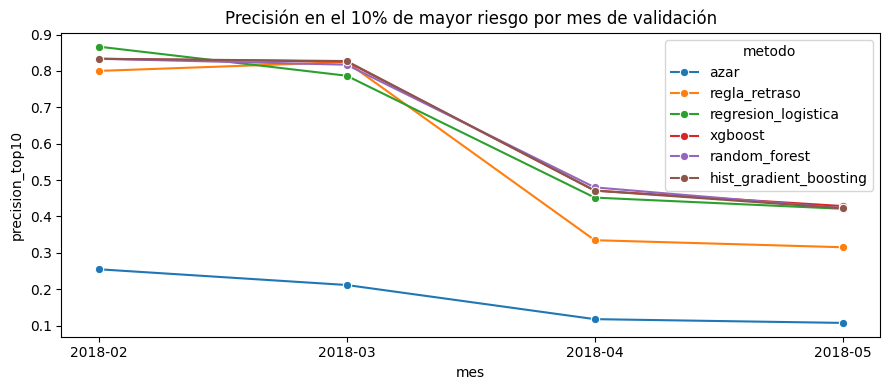

In [ ]:
#Comparaciones por mes
val = pd.DataFrame({
    "mes": fecha[~es_train].dt.to_period("M").astype(str).values,
    "real": y_test.values,
    "retraso": X_test_prep["dias_retraso"].astype("float64").fillna(0).values,
})
for nombre, m in modelos.items():
    val[nombre] = m.predict_proba(X_test)[:, 1]

filas = []
for mes, g in val.groupby("mes"):
    fila = {"mes": mes, "pedidos": len(g), "azar": g["real"].mean(),
            "regla_retraso": precision_top10(g["real"], g["retraso"])}
    for nombre in modelos:
        fila[nombre] = precision_top10(g["real"], g[nombre])
    filas.append(fila)
por_mes_val = pd.DataFrame(filas)
print(por_mes_val.round(4))

largo = por_mes_val.melt(id_vars=["mes", "pedidos"], var_name="metodo", value_name="precision_top10")
plt.figure(figsize=(9, 4))
sns.lineplot(data=largo, x="mes", y="precision_top10", hue="metodo", marker="o")
plt.title("Precisión en el 10% de mayor riesgo por mes de validación")
plt.tight_layout()
plt.show()

              variable  importancia
14    dias_dif_entrega     0.034654
0              n_items     0.033124
9   dias_entrega_total     0.014176
26           categoria     0.006223
11       ratio_entrega     0.005914
16      flete_por_item     0.002430
12       dias_despacho     0.002042
1         n_vendedores     0.001934
7            pct_flete     0.001439
3          flete_total     0.001149
25     estado_vendedor     0.001143
2         precio_total     0.000966
24      estado_cliente     0.000843
17         hora_compra     0.000637
13       dias_transito     0.000620


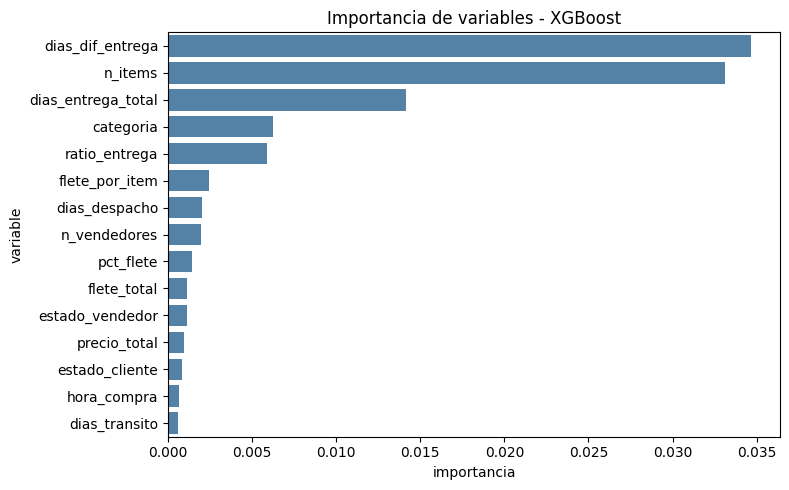

In [ ]:
from sklearn.inspection import permutation_importance

modelo = modelos["xgboost"]

X_sel = modelo[:2].transform(X_test)      # preparación + selección de variables
res = permutation_importance(modelo[2:], X_sel, y_test,
                             scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=1)

imp = (pd.DataFrame({"variable": X_sel.columns, "importancia": res.importances_mean})
         .sort_values("importancia", ascending=False))
print(imp.head(15))

plt.figure(figsize=(8, 5))
sns.barplot(data=imp.head(15), y="variable", x="importancia", color="steelblue")
plt.title("Importancia de variables - XGBoost")
plt.tight_layout()
plt.show()

Probabilidad promedio: 0.1495 | tasa real: 0.148
count    20724.0000
mean         0.1495
std          0.1901
min          0.0186
50%          0.0767
90%          0.3644
95%          0.7287
99%          0.8369
max          0.9335
dtype: float64
  decil  proba_media  tasa_real
0     1       0.0416     0.0482
1     2       0.0519     0.0521
2     3       0.0583     0.0579
3     4       0.0648     0.0690
4     5       0.0723     0.0666
5     6       0.0823     0.0666
6     7       0.0971     0.0902
7     8       0.1252     0.1207
8     9       0.2238     0.2288
9    10       0.6779     0.6797


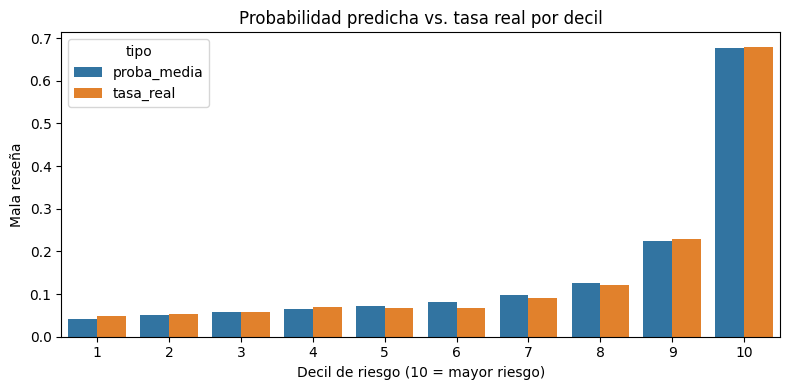

In [ ]:
#Validación probabilidades
proba_val = modelos["xgboost"].predict_proba(X_test)[:, 1]

print("Probabilidad promedio:", round(proba_val.mean(), 4), "| tasa real:", round(y_test.mean(), 4))
print(pd.Series(proba_val).describe(percentiles=[.5, .9, .95, .99]).round(4))

cal = pd.DataFrame({"proba": proba_val, "real": y_test.values})
cal["decil"] = pd.qcut(cal["proba"].rank(method="first"), 10, labels=range(1, 11))
tabla = (cal.groupby("decil", observed=True)
            .agg(proba_media=("proba", "mean"), tasa_real=("real", "mean"))
            .reset_index())
print(tabla.round(4))

largo = tabla.melt(id_vars="decil", var_name="tipo", value_name="valor")
plt.figure(figsize=(8, 4))
sns.barplot(data=largo, x="decil", y="valor", hue="tipo")
plt.xlabel("Decil de riesgo (10 = mayor riesgo)")
plt.ylabel("Mala reseña")
plt.title("Probabilidad predicha vs. tasa real por decil")
plt.tight_layout()
plt.show()

              variable  caida_auc  caida_top10  std_top10
0              n_items     0.0429       0.0869     0.0049
9   dias_entrega_total     0.0167       0.0107     0.0036
14    dias_dif_entrega     0.0161       0.0814     0.0041
26           categoria     0.0071       0.0023     0.0031
11       ratio_entrega     0.0054       0.0053     0.0031
12       dias_despacho     0.0037      -0.0001     0.0034
1         n_vendedores     0.0025       0.0207     0.0008
16      flete_por_item     0.0019      -0.0003     0.0027
24      estado_cliente     0.0016       0.0009     0.0024
25     estado_vendedor     0.0015      -0.0016     0.0018
5       fotos_promedio     0.0014      -0.0010     0.0008
7            pct_flete     0.0013      -0.0013     0.0031
3          flete_total     0.0010      -0.0009     0.0022
4         peso_total_g     0.0010       0.0021     0.0027
13       dias_transito     0.0010      -0.0024     0.0017


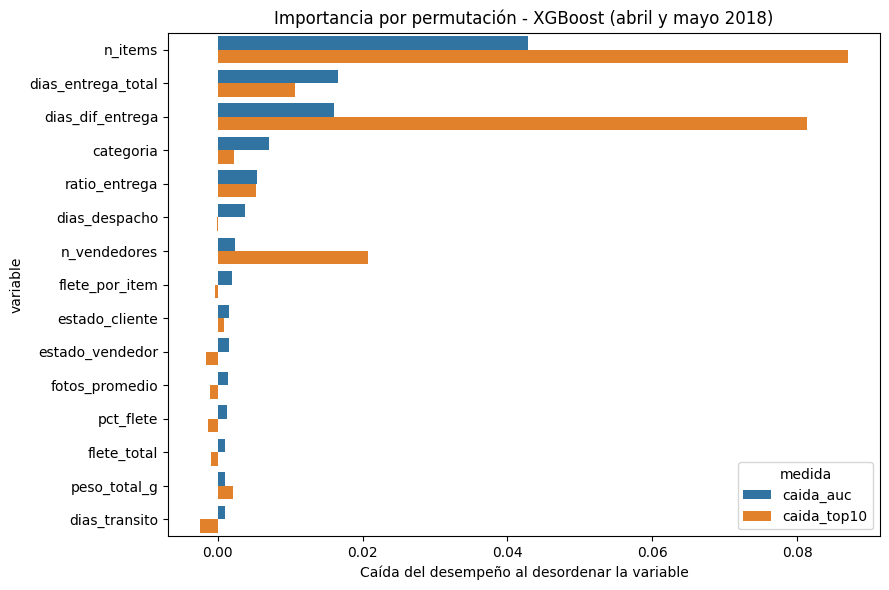

In [ ]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

elegido = "xgboost"
modelo = modelos[elegido]

def scorer_top10(est, X, y):
    return precision_top10(y, est.predict_proba(X)[:, 1])

# Solo un par de mesese abril y mayo
meses_val = fecha[~es_train].dt.to_period("M").astype(str).values
mask = np.isin(meses_val, ["2018-04", "2018-05"])

X_sel = modelo[:2].transform(X_test[mask])      # preparación + selección de variables
y_sel = y_test[mask]
resto = modelo[2:]                              # preprocesador + modelo ya entrenados

res = permutation_importance(
    resto, X_sel, y_sel,
    scoring={"top10": scorer_top10, "auc": "roc_auc"},
    n_repeats=10, random_state=42, n_jobs=-1,
)

imp = pd.DataFrame({
    "variable": X_sel.columns,
    "caida_auc": res["auc"].importances_mean,
    "caida_top10": res["top10"].importances_mean,
    "std_top10": res["top10"].importances_std,
}).sort_values("caida_auc", ascending=False)
print(imp.head(15).round(4))

top = imp.head(15).melt(id_vars="variable", value_vars=["caida_auc", "caida_top10"],
                        var_name="medida", value_name="caida")
plt.figure(figsize=(9, 6))
sns.barplot(data=top, y="variable", x="caida", hue="medida")
plt.xlabel("Caída del desempeño al desordenar la variable")
plt.title("Importancia por permutación - XGBoost (abril y mayo 2018)")
plt.tight_layout()
plt.show()

                grupo  caida_auc  caida_top10  std_top10
0  tiempos_de_entrega     0.1621       0.2445     0.0084
5   tamano_del_pedido     0.0600       0.1046     0.0036
2            producto     0.0084       0.0030     0.0025
1       valor_y_flete     0.0052       0.0079     0.0045
3           geografia     0.0039       0.0028     0.0015
6   momento_de_compra     0.0003       0.0009     0.0015
4                pago    -0.0006      -0.0035     0.0014


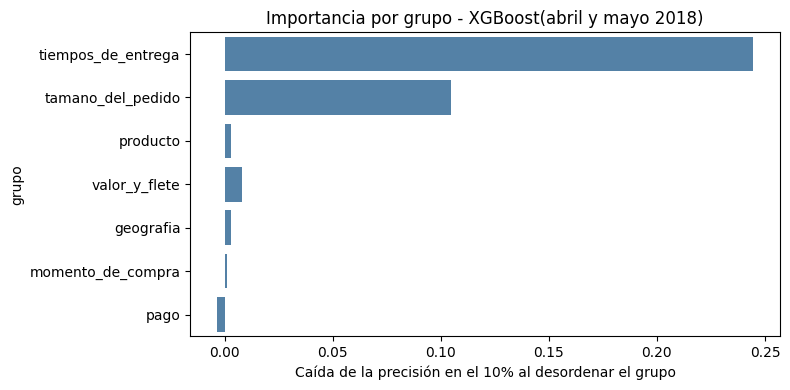

In [ ]:
grupos = {
    "tiempos_de_entrega": ["dias_dif_entrega", "dias_entrega_total", "dias_prometidos",
                           "ratio_entrega", "dias_despacho", "dias_transito"],
    "valor_y_flete":      ["precio_total", "flete_total", "pct_flete", "flete_mayor_precio",
                           "precio_por_item", "flete_por_item"],
    "producto":           ["categoria", "peso_total_g", "fotos_promedio"],
    "geografia":          ["estado_cliente", "estado_vendedor", "mismo_estado"],
    "pago":               ["tipo_pago", "cuotas_max", "pago_en_cuotas", "horas_aprobacion"],
    "tamano_del_pedido":  ["n_items", "n_vendedores", "multi_vendedor"],
    "momento_de_compra":  ["hora_compra", "dia_semana_compra", "compra_fin_semana"],
}

def importancia_grupo(pipe, X, y, columnas, n_rep=10, seed=42):
    rng = np.random.default_rng(seed)
    base_auc = roc_auc_score(y, pipe.predict_proba(X)[:, 1])
    base_top = scorer_top10(pipe, X, y)
    caidas_auc, caidas_top = [], []
    for _ in range(n_rep):
        idx = rng.permutation(len(X))           # misma permutación para todo el grupo
        Xp = X.copy()
        for c in columnas:
            Xp[c] = X[c].values[idx]
        caidas_auc.append(base_auc - roc_auc_score(y, pipe.predict_proba(Xp)[:, 1]))
        caidas_top.append(base_top - scorer_top10(pipe, Xp, y))
    return np.mean(caidas_auc), np.mean(caidas_top), np.std(caidas_top)

filas = []
for nombre, cols in grupos.items():
    a, t, s = importancia_grupo(resto, X_sel, y_sel, cols)
    filas.append({"grupo": nombre, "caida_auc": a, "caida_top10": t, "std_top10": s})
imp_grupos = pd.DataFrame(filas).sort_values("caida_auc", ascending=False)
print(imp_grupos.round(4))

plt.figure(figsize=(8, 4))
sns.barplot(data=imp_grupos, y="grupo", x="caida_top10", color="steelblue")
plt.xlabel("Caída de la precisión en el 10% al desordenar el grupo")
plt.title("Importancia por grupo - XGBoost(abril y mayo 2018)")
plt.tight_layout()
plt.show()

             pedidos  tasa_mala
items_grupo                    
1              69526     0.1199
2               5978     0.2591
3               1042     0.3090
4 o más          758     0.3509
                  pedidos  tasa_mala
vendedores_grupo                    
1                   76357     0.1311
2                     903     0.4806
3 o más                44     0.6591


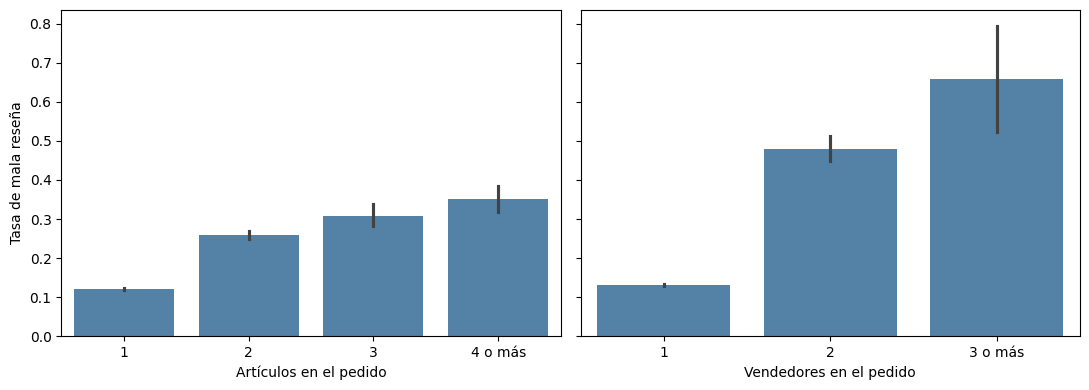

In [ ]:
datos = final[["n_items", "n_vendedores", "mala_resena"]].copy()
datos["n_items"] = pd.to_numeric(datos["n_items"], errors="coerce")
datos["n_vendedores"] = pd.to_numeric(datos["n_vendedores"], errors="coerce")
datos["items_grupo"] = pd.cut(datos["n_items"], [0, 1, 2, 3, np.inf], labels=["1", "2", "3", "4 o más"])
datos["vendedores_grupo"] = pd.cut(datos["n_vendedores"], [0, 1, 2, np.inf], labels=["1", "2", "3 o más"])

for col in ["items_grupo", "vendedores_grupo"]:
    print(datos.groupby(col, observed=True)["mala_resena"]
               .agg(pedidos="size", tasa_mala="mean").round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
sns.barplot(data=datos, x="items_grupo", y="mala_resena", color="steelblue", ax=ax[0])
sns.barplot(data=datos, x="vendedores_grupo", y="mala_resena", color="steelblue", ax=ax[1])
ax[0].set_xlabel("Artículos en el pedido"); ax[1].set_xlabel("Vendedores en el pedido")
ax[0].set_ylabel("Tasa de mala reseña"); ax[1].set_ylabel("")
plt.tight_layout()
plt.show()

In [ ]:
# Peso del número de artículos con un vendedor
cruce = (datos.groupby(["items_grupo", "vendedores_grupo"], observed=True)["mala_resena"]
              .agg(pedidos="size", tasa_mala="mean").round(4))
print(cruce)

#  Qué hay dentro del 10% de mayor riesgo del modelo (abril y mayo)
d = pd.DataFrame({
    "real": y_sel.values,
    "proba": modelos["xgboost"].predict_proba(X_test[mask])[:, 1],
    "multi_items": X_sel["n_items"].values > 1,
    "multi_vend": X_sel["n_vendedores"].values > 1,
    "con_retraso": X_test_prep[mask]["dias_retraso"].astype("float64").fillna(0).values > 0,
})
k = int(len(d) * 0.10)
d["top10"] = d["proba"].rank(method="first", ascending=False) <= k
d["tipo"] = np.select([d["multi_vend"], d["multi_items"], d["con_retraso"]],
                      ["varios_vendedores", "varios_items", "solo_retraso"], default="otros")

print(d.loc[d["top10"], ["multi_items", "multi_vend", "con_retraso"]].mean().round(3))
print(d[d["top10"]].groupby("tipo")["real"].agg(pedidos="size", tasa_mala="mean").round(4))

                              pedidos  tasa_mala
items_grupo vendedores_grupo                    
1           1                   69526     0.1199
2           1                    5261     0.2309
            2                     717     0.4658
3           1                     898     0.2762
            2                     120     0.5000
            3 o más                24     0.5833
4 o más     1                     672     0.3140
            2                      66     0.6061
            3 o más                20     0.7500
multi_items    0.481
multi_vend     0.170
con_retraso    0.485
dtype: float64
                   pedidos  tasa_mala
tipo                                 
otros                   97     0.1753
solo_retraso           602     0.5847
varios_items           419     0.2792
varios_vendedores      229     0.5022


conjunto                 train  validacion  diferencia
modelo                                                
hist_gradient_boosting  0.8069      0.7942      0.0128
random_forest           0.8814      0.7912      0.0902
regresion_logistica     0.7480      0.7825     -0.0345
xgboost                 0.8124      0.7936      0.0188
                modelo   conjunto  punto_de_corte  umbral  precision  recall     f1  pct_marcados
hist_gradient_boosting      train         top_10%  0.2358     0.5877  0.4491 0.5091        0.1000
hist_gradient_boosting validacion         top_10%  0.3695     0.6778  0.4581 0.5467        0.1000
         random_forest      train         top_10%  0.2315     0.5993  0.4581 0.5193        0.1000
         random_forest validacion         top_10%  0.3602     0.6758  0.4568 0.5451        0.1000
   regresion_logistica      train         top_10%  0.2557     0.5334  0.4077 0.4621        0.1000
   regresion_logistica validacion         top_10%  0.3165     0.6527  0.4411 0.526

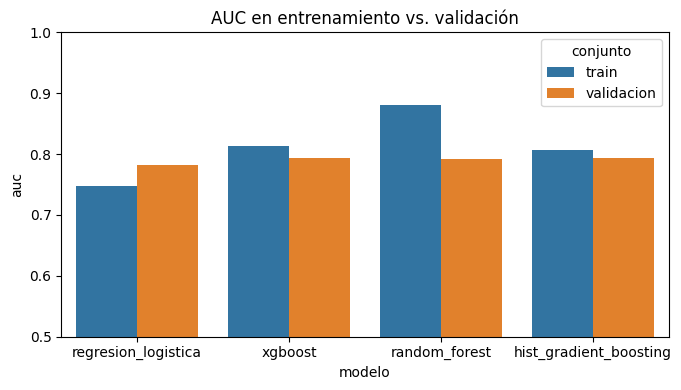

In [ ]:
# Métricas Modelo de Clasificacion
from sklearn.metrics import (roc_auc_score, f1_score, precision_score,
                             recall_score, precision_recall_curve)

def metricas(y_real, proba, umbral):
    pred = (proba >= umbral).astype(int)
    return {
        "umbral": float(umbral),
        "auc": roc_auc_score(y_real, proba),
        "precision": precision_score(y_real, pred, zero_division=0),
        "recall": recall_score(y_real, pred, zero_division=0),
        "f1": f1_score(y_real, pred, zero_division=0),
        "pct_marcados": pred.mean(),
    }

filas = []
for nombre, m in modelos.items():
    pr_tr = m.predict_proba(X_train)[:, 1]
    pr_va = m.predict_proba(X_test)[:, 1]

    # Umbral que maximiza F1, elegido solo con train
    p, r, t = precision_recall_curve(y_train, pr_tr)
    f1s = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    umbral_f1 = t[np.argmax(f1s)]

    for conjunto, yy, pr in [("train", y_train, pr_tr), ("validacion", y_test, pr_va)]:
        puntos = {
            "umbral_0.5": 0.5,
            "top_10%": np.quantile(pr, 0.90),      # marca el 10% de mayor riesgo
            "umbral_f1_train": umbral_f1,
        }
        for punto, u in puntos.items():
            filas.append({"modelo": nombre, "conjunto": conjunto,
                          "punto_de_corte": punto, **metricas(yy, pr, u)})

tabla = pd.DataFrame(filas)

# AUC (no depende del umbral)
auc = (tabla.drop_duplicates(["modelo", "conjunto"])
            .pivot(index="modelo", columns="conjunto", values="auc"))
auc["diferencia"] = auc["train"] - auc["validacion"]
print(auc.round(4))

# Precisión, recall y F1 por punto de corte
print(tabla[["modelo", "conjunto", "punto_de_corte", "umbral",
             "precision", "recall", "f1", "pct_marcados"]]
      .sort_values(["punto_de_corte", "modelo", "conjunto"])
      .round(4).to_string(index=False))

# Gráfico de AUC
auc_largo = (tabla.drop_duplicates(["modelo", "conjunto"])[["modelo", "conjunto", "auc"]])
plt.figure(figsize=(7, 4))
sns.barplot(data=auc_largo, x="modelo", y="auc", hue="conjunto")
plt.ylim(0.5, 1)
plt.title("AUC en entrenamiento vs. validación")
plt.tight_layout()
plt.show()

In [ ]:
import sys
print(sys.version)

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


### Modelo final y prueba del contrato

Entrenen el modelo final con todos los pedidos, guárdenlo como `modelo_riesgo.joblib` y comprueben que, **cargado desde el archivo**, predice con filas que solo traen las columnas del contrato:

In [ ]:
import joblib
elegido = "xgboost"

medianas_final = validar_fechas_pedido(X).attrs["medianas"]
modelo_final = armar_modelo(elegido, medianas_final)
modelo_final.fit(X, y)

joblib.dump(modelo_final, "modelo_riesgo.joblib")

['modelo_riesgo.joblib']

In [ ]:
from google.colab import files

files.download("modelo_riesgo.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import joblib
cargado = joblib.load("modelo_riesgo.joblib")
proba=cargado.predict_proba(pedidos[CONTRATO[:-1]].head(5))[:, 1]
predict=cargado.predict(pedidos[CONTRATO[:-1]].head(5))
print(proba)
print(predict)

[0.0642482  0.06867123 0.05161796 0.08862612 0.06895954]
[0 0 0 0 0]


In [ ]:
cargado = joblib.load("modelo_riesgo.joblib")
prueba=pedidos[pedidos['order_id']=="7753606fb1d0067848f8a1a7ae5abefa"]
proba=cargado.predict_proba(prueba[CONTRATO[:-1]].head(5))[:, 1]
predict=cargado.predict(prueba[CONTRATO[:-1]].head(5))
print(proba)
print(predict)

[0.7201184]
[1]


In [ ]:
proba = modelos["xgboost"].predict_proba(X_test)[:, 1]
alto = X_test[proba > 0.6][CONTRATO[:-1]].head(5)
print(alto.to_json(orient="records", date_format="iso"))


[{"order_id":"7753606fb1d0067848f8a1a7ae5abefa","order_purchase_timestamp":"2018-05-02T13:17:54.000","order_approved_at":"2018-05-02T15:58:53.000","order_delivered_carrier_date":"2018-05-04T15:20:00.000","order_delivered_customer_date":"2018-05-23T17:51:15.000","order_estimated_delivery_date":"2018-05-16T00:00:00.000","estado_cliente":"SP","n_items":2,"n_vendedores":1,"precio_total":119.98,"flete_total":17.76,"peso_total_g":1900.0,"fotos_promedio":1.0,"categoria":"beleza_saude","estado_vendedor":"SP","tipo_pago":"credit_card","cuotas_max":1.0}]


In [ ]:
proba = modelos["xgboost"].predict_proba(X_test)[:, 1]

alto = X_test[proba > 0.6][CONTRATO[:-1]].head(5)

# Guardar como JSON
alto.to_json(
    "pruebas_xgboost.json",
    orient="records",
    date_format="iso",
    force_ascii=False,
    indent=4
)

files.download("pruebas_xgboost.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Preguntas (respóndanlas en Markdown, con cifras de sus salidas)

1. ¿Cuánto mejora su modelo sobre la regla de retraso? ¿Y sobre el azar?
2. ¿Qué tres variables pesan más y por qué tiene sentido para el negocio?
3. ¿Qué pasaría con su modelo en un periodo con muy pocos retrasos?

Escogí XGBoost por dos razones:
Apesar que en la validación global es similar a Random Forest y HistGradiantBoosting, es decir arriba de 0.67, XGBoost logra obtener 0.0024 (0.35%) por encima de HistGradiantBoosting. Además, al revisar cada una de las métricas de los modelos de clasificación es quien tiene menor diferencia entre la precision del train y el test (0.085), es decir, tiene menos sobreajuste que los demás, asimismo, métricas como f1-score y recall existe menor sobreajuste.

1. Cuánta mejora el modelo contra el azar: el modelo multiplica la precisión por 4.6 en toda la validación.
Contra la regla, en toda la validación: la mejora es de 4.7 puntos. Es una mejora modesta porque la cifra global contiene varios meses  con más retrasos: en marzo, la regla y el modelo casi empatan (0.824 contra 0.826).Pero en abril y mayo (0.471 y 0.428) donde no hay muchos retrasos las métricas son bajas pero son aún más bajas las métricas de la regla, en abril el modelo supera a la regla en 13.6 puntos y en mayo por 11.3 puntos. Esto nos permite inferir que los retrasos son el factor o es uno de lo más importante que determinan si es o no una mala reseña.

2. las tres variables más importantes son: ** dias_dif_entrega, n_items, dias_entrega_total**. Al observar que la regla perdia por puntos se infiere inmediantamente que los días de retraso son clave para una mala resena.
Tiene mucho sentido porque el cliente califica peor cuando no se cumple con una fecha de entrega pero su disgusto puede ser mayor a medida incrementan esos días de retraso. Por otro lado, la tasa de mala de reseña aumenta a medida aumenta la cantidad de items por orden pasando de 12.0% con un artículo, 25.9% con dos, 30.8% con tres y 35.1% con cuatro o más. Por otro lado, esto está relacionado con la cantidad de vendederos en cuanto más vendedores intervengan en un pedido más alto puede ser la tasa de retrasos y de mala reseña. Con un vendedor es de 13.1%, con dos sube a 48.1% (903 pedidos), y con tres o más llega a 65.9% (solo 44 pedidos). Conclusión: los pedidos con más items y vendedores tienen más oportunidad de llegar después de la fecha estimada ampliando sus días de entrega total.

3. Realice las pruebas con abril y mayo, meses en los cuáles pocos pedidos tienen retraso (4.4% y 6.5% de las ordenes) y el modelo a pesar de tener métricas bajas sigue siendo mejor que la regla por 13.6 y esto se debe a que no solo depende una variable sino que es aquí donde el conjunto de variables ayudan al modelo a identificar las malas reseñas.



## Parte 3 · Pregunta abierta

Opción elegida: **[3A pronóstico de junio / 3B segmentación]**

Justifiquen la elección y cada decisión. Si eligen 3A, guarden `pronostico_junio.csv` con columnas `fecha, pronostico, bajo, alto` (30 filas, del 1 al 30 de junio de 2018).

In [ ]:
sellers= text("""

WITH estado AS (
  SELECT
    o.order_id,
    s.seller_state,
    s.seller_id,
    p.product_category_name,
    oi.price,
    oi.freight_value
  FROM final.orders o
  JOIN final.order_items oi ON oi.order_id = o.order_id
  JOIN final.sellers s ON s.seller_id = oi.seller_id
  JOIN final.products p ON p.product_id = oi.product_id
  WHERE o.order_status = 'delivered'  AND o.order_delivered_customer_date IS NOT NULL
  AND TRIM(o.order_delivered_customer_date::text) <> ''
),
pedidos as (
    SELECT
        o.order_id,
        o.order_purchase_timestamp,
        o.order_approved_at,
        o.order_delivered_carrier_date,
        o.order_delivered_customer_date,
        o.order_estimated_delivery_date,
        c.customer_state AS estado_cliente,
        (
           o.order_delivered_customer_date::date
            - o.order_purchase_timestamp::date
        ) AS dias_entrega,

        (
            o.order_delivered_customer_date::date
            - o.order_estimated_delivery_date::date
        ) AS diferencia_dias_entrega,

        CASE

            WHEN o.order_delivered_customer_date::date
                 > o.order_estimated_delivery_date::date
                THEN 'Retrasado'
            WHEN o.order_delivered_customer_date::date
                 < o.order_estimated_delivery_date::date
                THEN 'Adelantado'
            ELSE 'A tiempo'
        END AS estado_entrega,

        CASE
            WHEN o.order_delivered_customer_date::date
                 > o.order_estimated_delivery_date::date
            THEN (
                o.order_delivered_customer_date::date
                - o.order_estimated_delivery_date::date
            )
            ELSE 0
        END AS dias_retraso,

        CASE
            WHEN o.order_delivered_customer_date::date
                 < o.order_estimated_delivery_date::date
            THEN (
                o.order_estimated_delivery_date::date
                - o.order_delivered_customer_date::date
            )
            ELSE 0
        END AS dias_adelanto

    FROM final.orders o
    JOIN final.customers c
        ON o.customer_id = c.customer_id

),

items AS (
  SELECT
    order_id,
    COUNT(order_item_id) AS n_items,
    COUNT(DISTINCT seller_id) AS n_vendedores,
    SUM(price) AS precio_total,
    SUM(freight_value) AS flete_total
  FROM final.order_items
  GROUP BY order_id
),
productos AS (
  SELECT
    oi.order_id,
    SUM(p.product_weight_g) AS peso_total_g,
    AVG(p.product_photos_qty) AS fotos_promedio
  FROM final.order_items oi
  LEFT JOIN final.products p ON p.product_id = oi.product_id
  GROUP BY oi.order_id
),
pagos AS (
  SELECT
    order_id,
    payment_type,
    payment_value,
    MAX(payment_installments) OVER (PARTITION BY order_id) AS cuotas_max,
    ROW_NUMBER() OVER (
      PARTITION BY order_id
      ORDER BY payment_value DESC, payment_sequential
    ) AS rn
  FROM final.order_payments
),
resenas AS (
  SELECT
    order_id,
    review_score,
    ROW_NUMBER() OVER (
      PARTITION BY order_id
      ORDER BY review_answer_timestamp DESC, review_id
    ) AS rn
  FROM final.order_reviews
),
tabla AS (
  SELECT
    o.order_id,
    o.order_purchase_timestamp,
    o.order_approved_at,
    o.order_delivered_carrier_date,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    c.customer_state AS estado_cliente,
    i.n_items,
    i.n_vendedores,
    i.precio_total,
    i.flete_total,
    pr.peso_total_g,
    pr.fotos_promedio,
    e.product_category_name AS categoria,
    e.seller_state AS estado_vendedor,
    pa.payment_type AS tipo_pago,
    pa.cuotas_max,
    CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END AS mala_resena,
    e.seller_id,
    e.price,
    e.freight_value,
    p.dias_entrega,
    p.diferencia_dias_entrega,
    p.estado_entrega,
    p.dias_retraso,
    p.dias_adelanto

  FROM final.orders o
  JOIN final.customers c ON c.customer_id = o.customer_id
  JOIN  estado e ON e.order_id = o.order_id
  JOIN  items i ON i.order_id = o.order_id
  JOIN  productos pr ON pr.order_id = o.order_id
  JOIN  pagos pa ON pa.order_id = o.order_id AND pa.rn = 1
  JOIN resenas r ON r.order_id = o.order_id AND r.rn = 1
  JOIN pedidos p ON p.order_id = o.order_id
  WHERE o.order_status = 'delivered'  AND o.order_delivered_customer_date IS NOT NULL
  AND TRIM(o.order_delivered_customer_date::text) <> ''
  AND o.order_delivered_customer_date <> '0001-01-01 00:00:00'
  AND o.order_purchase_timestamp< '2018-06-01'

)
SELECT * FROM tabla
""")

with motor.connect() as connection:
    df_sellers = pd.read_sql_query(sellers, connection)

# Verificación: una sola fila por pedido
df_sellers["order_id"].is_unique, df_sellers.shape

(False, (88355, 26))

In [ ]:


import numpy as np
import pandas as pd



df = df_sellers.copy()

columnas_necesarias = [
    "seller_id",
    "estado_vendedor",
    "order_id",
    "estado_cliente",
    "n_items",
    "price",
    "flete_total",
    "categoria",
    "dias_entrega",
    "diferencia_dias_entrega",
    "dias_retraso",
    "dias_adelanto",
    "order_purchase_timestamp"
]

faltantes = [col for col in columnas_necesarias if col not in df.columns]

if faltantes:
    raise ValueError(f"Faltan columnas en df_sellers: {faltantes}")


#Categorías de más peddidos


pedidos_categoria = (
    df.dropna(subset=["categoria", "seller_id", "order_id"])
      .groupby(["seller_id", "categoria"], as_index=False)
      .agg(
          pedidos_categoria=("order_id", "nunique")
      )
)


idx_categoria = (
    pedidos_categoria
    .groupby("seller_id")["pedidos_categoria"]
    .idxmax()
)

categoria_principal = (
    pedidos_categoria
    .loc[idx_categoria, [
        "seller_id",
        "categoria",
        "pedidos_categoria"
    ]]
    .rename(columns={
        "categoria": "categoria_mas_pedidos",
        "pedidos_categoria": "pedidos_categoria_principal"
    })
)


# Agrupaciones por sellers

df_pedidos = (
    df.sort_values("order_purchase_timestamp")
      .drop_duplicates(subset=["seller_id", "order_id"])
      .copy()
)


df_pedidos["pedido_retrasado"] = (
    df_pedidos["diferencia_dias_entrega"] > 0
).astype(int)


df_pedidos["pedido_adelantado"] = (
    df_pedidos["diferencia_dias_entrega"] < 0
).astype(int)

#
df_pedidos["mismo_estado"] = (
    df_pedidos["estado_cliente"].notna()
    & df_pedidos["estado_vendedor"].notna()
    & (
        df_pedidos["estado_cliente"]
        == df_pedidos["estado_vendedor"]
    )
).astype(int)


df_pedidos["dias_retraso_solo_retrasados"] = (
    df_pedidos["dias_retraso"]
    .where(df_pedidos["pedido_retrasado"] == 1)
)


#Métricas
df_cluster_sellers = (
    df_pedidos
    .groupby("seller_id", as_index=False)
    .agg(
        estado_seller=("estado_vendedor", "first"),


        cantidad_pedidos=("order_id", "nunique"),

        n_items_vendidos=("n_items", "sum"),

        # Medianas
        monto_mediana=("price", "median"),
        flete_mediana=("flete_total", "median"),
        pedidos_retrasados_mediana=("pedido_retrasado", "median"),
        pedidos_adelantados_mediana=("pedido_adelantado", "median"),
        pedidos_mismo_estado_mediana=("mismo_estado", "median"),
        dias_entrega_mediana=("dias_entrega", "median"),

        # Conteos reales
        pedidos_retrasados=("pedido_retrasado", "sum"),
        pedidos_adelantados=("pedido_adelantado", "sum"),
        pedidos_mismo_estado=("mismo_estado", "sum"),

        # Mediana
        dias_retraso_mediana=(
            "dias_retraso_solo_retrasados",
            lambda x: x.median() if x.notna().any() else 0
        ),

        estados_cliente_diferentes=("estado_cliente", "nunique"),
        categorias_diferentes=("categoria", "nunique")
    )
)


df_cluster_sellers = df_cluster_sellers.merge(
    categoria_principal,
    on="seller_id",
    how="left"
)


#Calcular Tsas

denominador_pedidos = (
    df_cluster_sellers["cantidad_pedidos"].replace(0, np.nan)
)

df_cluster_sellers["tasa_pedidos_retrasados"] = (
    df_cluster_sellers["pedidos_retrasados"]
    / denominador_pedidos
)


df_cluster_sellers["tasa_pedidos_adelantados"] = (
    df_cluster_sellers["pedidos_adelantados"]
    / denominador_pedidos
)


df_cluster_sellers["tasa_pedidos_mismo_estado"] = (
    df_cluster_sellers["pedidos_mismo_estado"]
    / denominador_pedidos
)


df_cluster_sellers["flete_relativo"] = (
    df_cluster_sellers["flete_mediana"]
    / df_cluster_sellers["monto_mediana"].replace(0, np.nan)
)


df_cluster_sellers["tasa_retraso_dias"] = (
    df_cluster_sellers["pedidos_retrasados"]
    * df_cluster_sellers["dias_retraso_mediana"]
    / denominador_pedidos
)




columnas_redondear = df_cluster_sellers.select_dtypes(
    include="number"
).columns

df_cluster_sellers[columnas_redondear] = (
    df_cluster_sellers[columnas_redondear].round(4)
)


#Resultados

print("Dimensiones:", df_cluster_sellers.shape)

print(
    "¿Un seller por fila?:",
    df_cluster_sellers["seller_id"].is_unique
)

print(
    "Vendedores sin categoría principal:",
    df_cluster_sellers["categoria_mas_pedidos"].isna().sum()
)

print(
    "Vendedores con más de un pedido:",
    (df_cluster_sellers["cantidad_pedidos"] > 1).sum()
)

display(df_cluster_sellers.head())



Dimensiones: (2441, 23)
¿Un seller por fila?: True
Vendedores sin categoría principal: 57
Vendedores con más de un pedido: 1977


,seller_id,estado_seller,cantidad_pedidos,n_items_vendidos,monto_mediana,flete_mediana,pedidos_retrasados_mediana,pedidos_adelantados_mediana,pedidos_mismo_estado_mediana,dias_entrega_mediana,...,dias_retraso_mediana,estados_cliente_diferentes,categorias_diferentes,categoria_mas_pedidos,pedidos_categoria_principal,tasa_pedidos_retrasados,tasa_pedidos_adelantados,tasa_pedidos_mismo_estado,flete_relativo,tasa_retraso_dias
0,0015a82c2db000af6aaaf3ae2ecb0532,SP,3,3,895.00,21.020,0.0,1.0,0.0,11.0,...,0.0,2,1,eletroportateis,3.0,0.0000,1.0000,0.0000,0.0235,0.0000
1,001cca7ae9ae17fb1caed9dfb1094831,ES,189,229,99.00,38.200,0.0,1.0,0.0,11.0,...,4.0,17,2,ferramentas_jardim,168.0,0.0582,0.9365,0.0212,0.3859,0.2328
2,002100f778ceb8431b7a1020ff7ab48f,SP,50,56,17.90,15.100,0.0,1.0,0.0,14.0,...,5.0,13,1,moveis_decoracao,50.0,0.1800,0.8200,0.4400,0.8436,0.9000
3,003554e2dce176b5555353e4f3555ac8,GO,1,1,120.00,19.380,0.0,1.0,0.0,4.0,...,0.0,1,0,NaN,NaN,0.0000,1.0000,0.0000,0.1615,0.0000
4,004c9cd9d87a3c30c522c48c4fc07416,SP,154,167,109.99,17.965,0.0,1.0,0.0,12.0,...,6.5,18,1,cama_mesa_banho,143.0,0.0649,0.9156,0.3571,0.1633,0.4221


In [ ]:
df_cluster_sellers.columns

Index(['seller_id', 'estado_seller', 'cantidad_pedidos', 'n_items_vendidos',
       'monto_mediana', 'flete_mediana', 'pedidos_retrasados_mediana',
       'pedidos_adelantados_mediana', 'pedidos_mismo_estado_mediana',
       'dias_entrega_mediana', 'pedidos_retrasados', 'pedidos_adelantados',
       'pedidos_mismo_estado', 'dias_retraso_mediana',
       'estados_cliente_diferentes', 'categorias_diferentes',
       'categoria_mas_pedidos', 'pedidos_categoria_principal',
       'tasa_pedidos_retrasados', 'tasa_pedidos_adelantados',
       'tasa_pedidos_mismo_estado', 'flete_relativo', 'tasa_retraso_dias'],
      dtype='object')

In [ ]:
df_cluster_sellers=df_cluster_sellers[df_cluster_sellers["cantidad_pedidos"]>=10]

In [ ]:
df_cluster_sellers["categoria_mas_pedidos"] = (
    df_cluster_sellers["categoria_mas_pedidos"]
    .str.split("_")
    .str[0]
)

# Check the resulting categories
print(df_cluster_sellers["categoria_mas_pedidos"] .value_counts(dropna=False))
print("Categorías únicas:", df_cluster_sellers["categoria_mas_pedidos"] .nunique())

categoria_mas_pedidos
esporte             112
beleza              104
moveis               93
utilidades           82
informatica          66
cama                 57
brinquedos           52
automotivo           43
fashion              34
telefonia            31
bebes                30
perfumaria           28
pet                  27
ferramentas          27
cool                 26
relogios             24
papelaria            19
construcao           17
livros               17
eletronicos          15
eletroportateis      14
eletrodomesticos     11
consoles              9
alimentos             8
climatizacao          8
malas                 8
instrumentos          7
casa                  6
industria             4
cine                  3
NaN                   3
artigos               2
bebidas               2
sinalizacao           2
artes                 2
portateis             2
market                2
pcs                   1
dvds                  1
audio                 1
la                

In [ ]:


#  Identificar las 12 categorías más frecuentes, excluyendo NaN
top_12_categorias = (
    df_cluster_sellers["categoria_mas_pedidos"]
    .dropna()
    .value_counts()
    .head(15)
    .index
)


df_cluster_sellers["categoria_mas_pedidos"] = df_cluster_sellers["categoria_mas_pedidos"].where(
    df_cluster_sellers["categoria_mas_pedidos"].isin(top_12_categorias) |df_cluster_sellers["categoria_mas_pedidos"].isna(),
    "otros"
)

print(df_cluster_sellers["categoria_mas_pedidos"].value_counts())
print("Total de categorías:", df_cluster_sellers["categoria_mas_pedidos"].nunique())

categoria_mas_pedidos
otros          188
esporte        112
beleza         104
moveis          93
utilidades      82
informatica     66
cama            57
brinquedos      52
automotivo      43
fashion         34
telefonia       31
bebes           30
perfumaria      28
ferramentas     27
pet             27
cool            26
Name: count, dtype: int64
Total de categorías: 16


In [ ]:


import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    FunctionTransformer,
    StandardScaler,
    OneHotEncoder
)
from sklearn.pipeline import make_pipeline



con_log = [
    "cantidad_pedidos",
     "monto_mediana",
     'flete_mediana',
     'pedidos_retrasados',
      #'pedidos_adelantados',
      'dias_entrega_mediana',
      'dias_retraso_mediana',
      'categorias_diferentes',
      'tasa_pedidos_retrasados',  'flete_relativo', 'tasa_retraso_dias'
]

sin_log = [
    "estados_cliente_diferentes",
    #"categorias_diferentes",
]

categoricas = []

features = con_log + sin_log + categoricas
features_numericas=con_log + sin_log

preparacion = make_pipeline(
    ColumnTransformer(
        transformers=[
            ("log", FunctionTransformer(np.log1p), con_log),
            ("igual", "passthrough", sin_log),
            (
                "estado",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ),
                categoricas
            ),
        ],
        remainder="drop"
    ),
    StandardScaler()
)

X = preparacion.fit_transform(df_cluster_sellers[features])

print("Dimensiones de X:", X.shape)


Dimensiones de X: (1003, 11)


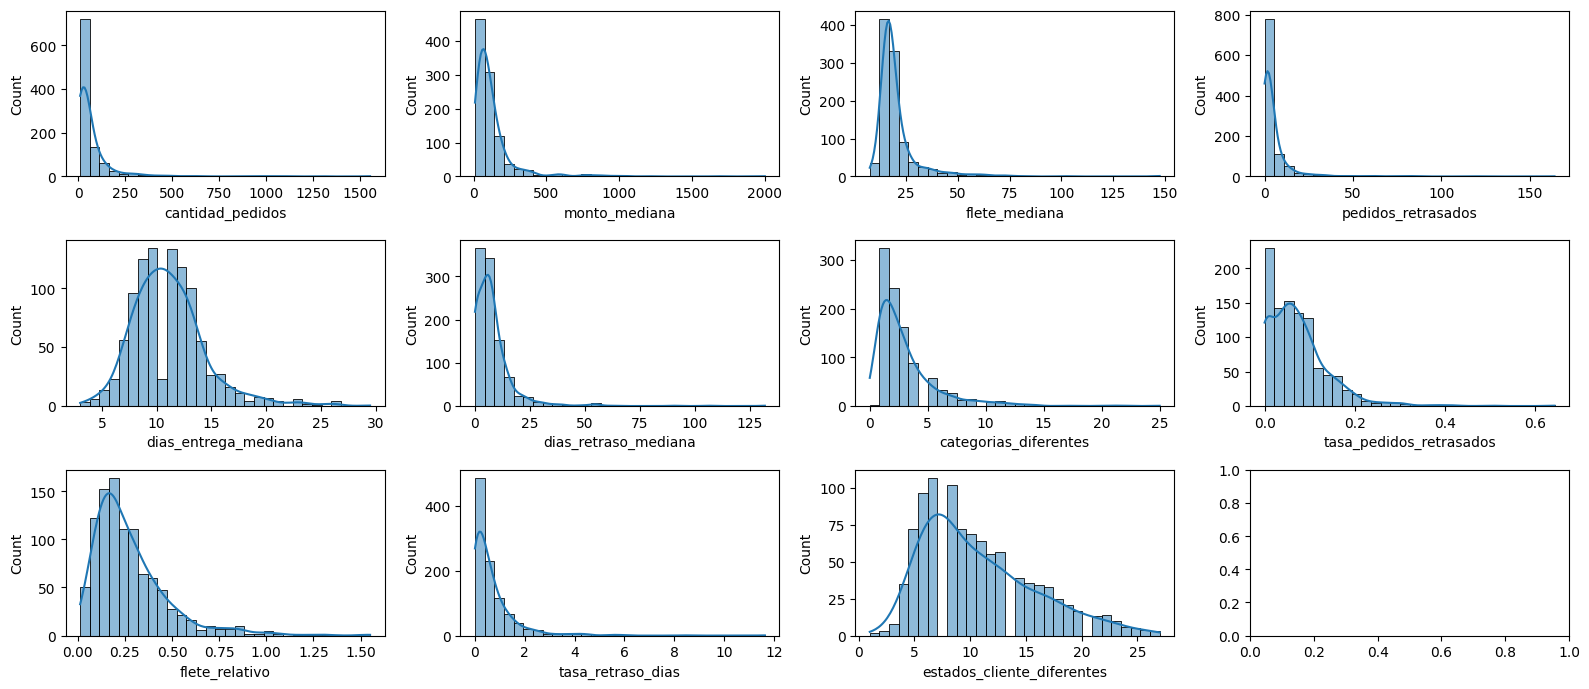

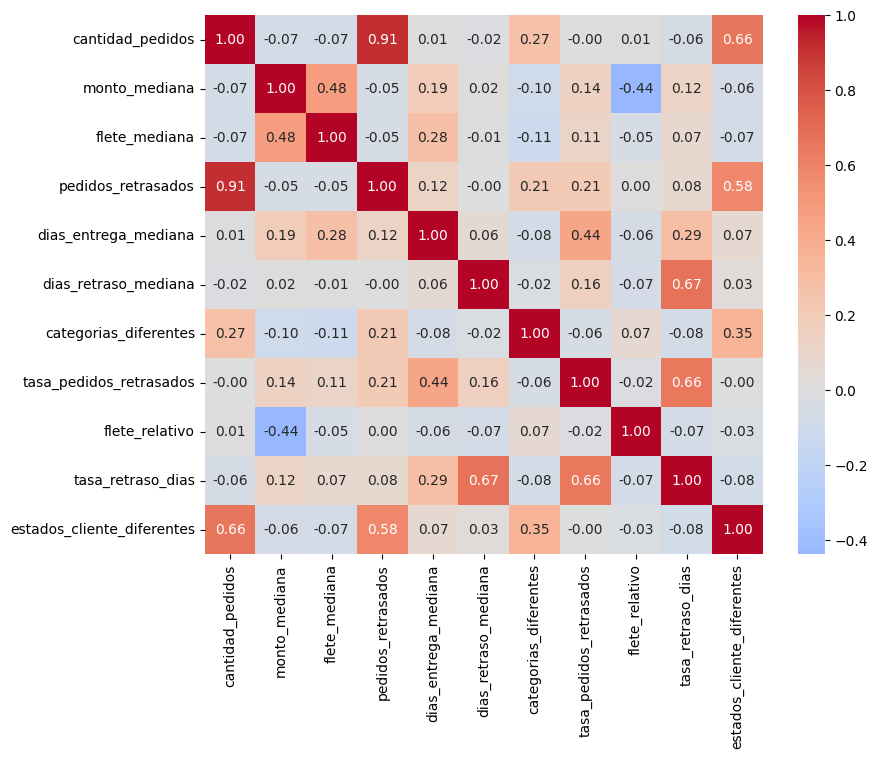

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features_numericas):
    sns.histplot(df_cluster_sellers[col], bins=30, kde=True, ax=ax)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(df_cluster_sellers[features_numericas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()


In [ ]:
from sklearn.datasets import make_blobs, load_digits
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.metrics import silhouette_score
resultados = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    resultados.append({"k": k, "inercia": km.inertia_, "silueta": silhouette_score(X, km.labels_)})

resultados = pd.DataFrame(resultados)
resultados.round(3)

,k,inercia,silueta
0,2,8878.626,0.178
1,3,7401.958,0.198
2,4,6624.771,0.173
3,5,6080.329,0.169
4,6,5683.648,0.173


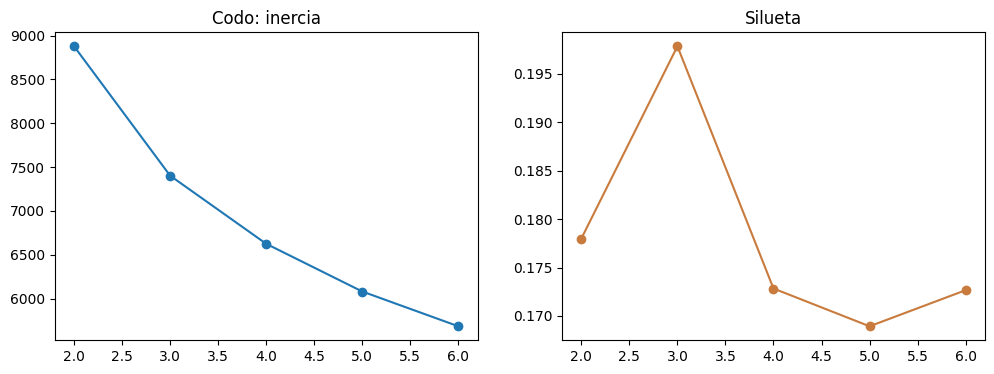

In [ ]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(12, 4))
izq.plot(resultados["k"], resultados["inercia"], marker="o")
izq.set_title("Codo: inercia")
der.plot(resultados["k"], resultados["silueta"], marker="o", color="#C97B3D")
der.set_title("Silueta")
plt.show()

In [ ]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
df_cluster_sellers["segmento"] = km3.labels_
df_cluster_sellers["segmento"].value_counts().sort_index()

,count
segmento,
0,305
1,359
2,339


In [ ]:
perfil = df_cluster_sellers.groupby("segmento")[features_numericas].median()
perfil.round(2)

,cantidad_pedidos,monto_mediana,flete_mediana,pedidos_retrasados,dias_entrega_mediana,dias_retraso_mediana,categorias_diferentes,tasa_pedidos_retrasados,flete_relativo,tasa_retraso_dias,estados_cliente_diferentes
segmento,,,,,,,,,,,
0,109.0,68.90,16.28,7.0,11.0,7.0,3.0,0.06,0.26,0.43,16.0
1,19.0,75.00,16.79,0.0,10.0,0.0,2.0,0.00,0.24,0.00,7.0
2,23.0,109.78,18.54,2.0,12.0,10.0,2.0,0.10,0.19,1.06,8.0


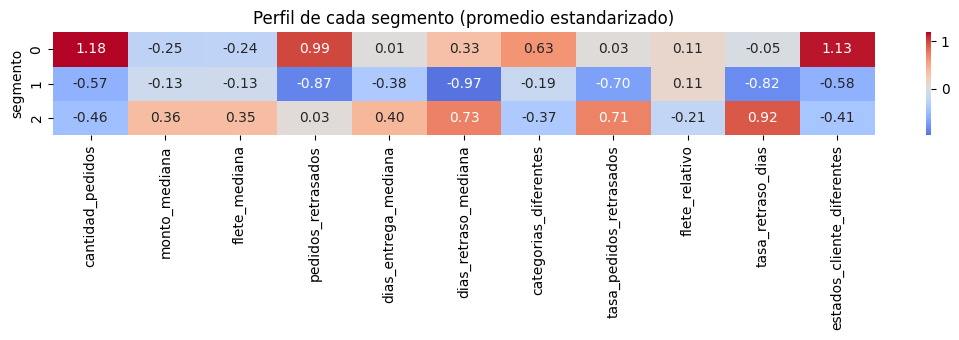

          cantidad_pedidos  monto_mediana  flete_mediana  pedidos_retrasados  \
segmento                                                                       
0                    109.0          68.90          16.28                 7.0   
1                     19.0          75.00          16.79                 0.0   
2                     23.0         109.78          18.54                 2.0   

          dias_entrega_mediana  dias_retraso_mediana  categorias_diferentes  \
segmento                                                                      
0                         11.0                   7.0                    3.0   
1                         10.0                   0.0                    2.0   
2                         12.0                  10.0                    2.0   

          tasa_pedidos_retrasados  flete_relativo  tasa_retraso_dias  \
segmento                                                               
0                            0.06            0.26          

In [ ]:
seg = df_cluster_sellers["segmento"].to_numpy()
perfil_z = pd.DataFrame(X, columns=features).groupby(seg).mean()

plt.figure(figsize=(11, 3.5))
sns.heatmap(perfil_z, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Perfil de cada segmento (promedio estandarizado)")
plt.ylabel("segmento")
plt.tight_layout()
plt.show()

print(df_cluster_sellers.groupby("segmento")[ features].median().round(2))

cantidad_pedidos 1.0
monto_mediana 1.0
Silueta k=3: 0.198


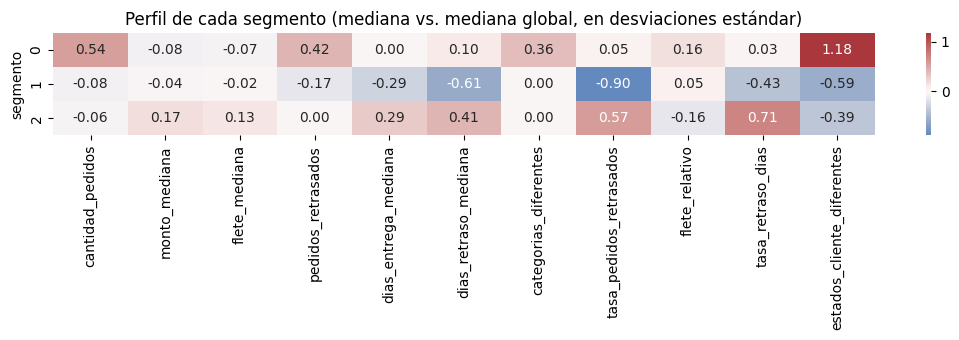

In [ ]:

#Validar desviaciones
for c in ["cantidad_pedidos", "monto_mediana"]:
    print(c, round(pd.Series(X[:, features.index(c)]).corr(
        df_cluster_sellers[c].reset_index(drop=True), method="spearman"), 3))
print("Silueta k=3:", round(silhouette_score(X, df_cluster_sellers["segmento"].values), 3))   # ≈ 0.198


perfil = df_cluster_sellers.groupby("segmento")[features].median()
z = (perfil - df_cluster_sellers[features].median()) / df_cluster_sellers[features].std()
plt.figure(figsize=(11, 3.5))
sns.heatmap(z, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Perfil de cada segmento (mediana vs. mediana global, en desviaciones estándar)")
plt.tight_layout()
plt.show()

In [ ]:
#Validar PCA
from sklearn.decomposition import PCA
pca = PCA()
pca.fit(X)
pca.explained_variance_ratio_.round(3)

array([0.299, 0.228, 0.167, 0.102, 0.072, 0.058, 0.044, 0.012, 0.009,
       0.005, 0.003])

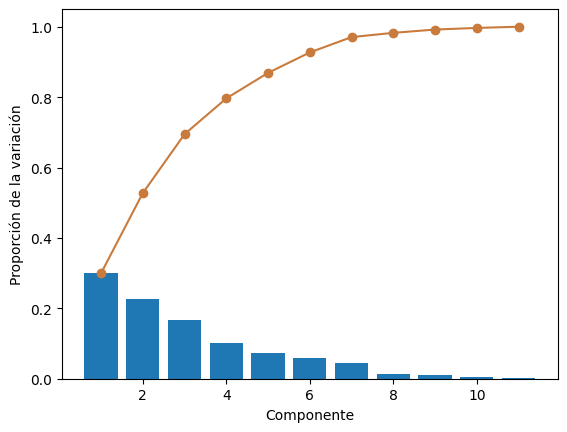

In [ ]:
plt.bar(range(1, 12), pca.explained_variance_ratio_)
plt.plot(range(1, 12), pca.explained_variance_ratio_.cumsum(), marker="o", color="#C97B3D")
plt.xlabel("Componente")
plt.ylabel("Proporción de la variación")
plt.show()

In [ ]:
cargas = pd.DataFrame(pca.components_[:2], columns=features, index=["Componente 1", "Componente 2"])
cargas.round(2)

,cantidad_pedidos,monto_mediana,flete_mediana,pedidos_retrasados,dias_entrega_mediana,dias_retraso_mediana,categorias_diferentes,tasa_pedidos_retrasados,flete_relativo,tasa_retraso_dias,estados_cliente_diferentes
Componente 1,0.38,0.02,0.02,0.51,0.21,0.39,0.15,0.34,-0.02,0.34,0.38
Componente 2,-0.35,0.43,0.34,-0.12,0.28,0.14,-0.28,0.30,-0.30,0.33,-0.30


PC1: 29.9% | PC2: 22.8% | Total conservado: 52.7%


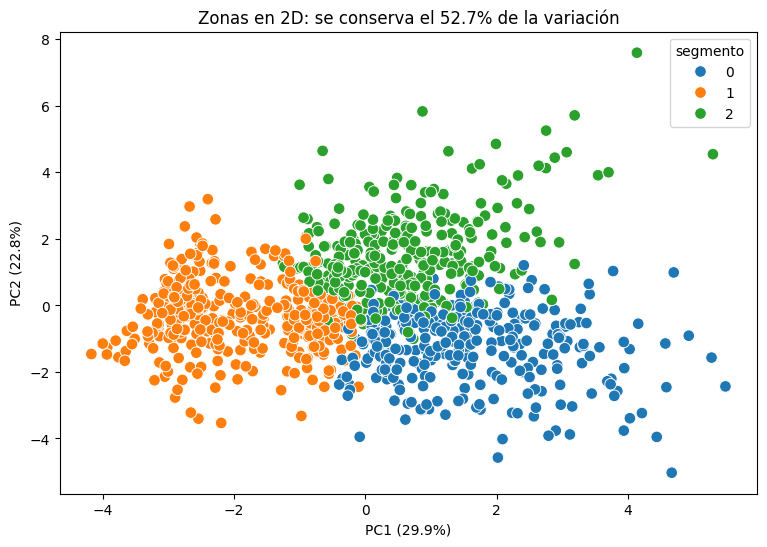

In [ ]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)
df_cluster_sellers["pc1"], df_cluster_sellers["pc2"] = coords[:, 0], coords[:, 1]

var = pca.explained_variance_ratio_
print(f"PC1: {var[0]:.1%} | PC2: {var[1]:.1%} | Total conservado: {var.sum():.1%}")

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_cluster_sellers, x="pc1", y="pc2", hue="segmento", palette="tab10", s=70)
plt.xlabel(f"PC1 ({var[0]:.1%})")
plt.ylabel(f"PC2 ({var[1]:.1%})")
plt.title(f"Zonas en 2D: se conserva el {var.sum():.1%} de la variación")
plt.show()

In [ ]:
# 1. Mapeo directo, según el heatmap actual
nombres = {
    0: "Alta demanda y amplia cobertura",
    1: "Bajo volumen y entregas puntual",
    2: "Ticket alto con retrasos",
}
df_cluster_sellers["segmento_nombre"] = df_cluster_sellers["segmento"].map(nombres)

# Verificación: no debe haber nulos, y los tamaños deben coincidir con los de antes
print(df_cluster_sellers["segmento_nombre"].isna().sum())
print(df_cluster_sellers["segmento_nombre"].value_counts())

0
segmento_nombre
Bajo volumen y entregas puntual    359
Ticket alto con retrasos           339
Alta demanda y amplia cobertura    305
Name: count, dtype: int64


In [ ]:
df_cluster_sellers.columns

Index(['seller_id', 'estado_seller', 'cantidad_pedidos', 'n_items_vendidos',
       'monto_mediana', 'flete_mediana', 'pedidos_retrasados_mediana',
       'pedidos_adelantados_mediana', 'pedidos_mismo_estado_mediana',
       'dias_entrega_mediana', 'pedidos_retrasados', 'pedidos_adelantados',
       'pedidos_mismo_estado', 'dias_retraso_mediana',
       'estados_cliente_diferentes', 'categorias_diferentes',
       'categoria_mas_pedidos', 'pedidos_categoria_principal',
       'tasa_pedidos_retrasados', 'tasa_pedidos_adelantados',
       'tasa_pedidos_mismo_estado', 'flete_relativo', 'tasa_retraso_dias',
       'segmento', 'pc1', 'pc2', 'segmento_nombre'],
      dtype='object')

In [ ]:
joblib.dump(
    {"scaler": preparacion, "kmeans": km3},
    "modelo_sellers.joblib",
)
from google.colab import files
files.download("modelo_sellers.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Silueta global: 0.198
          vendedores  silueta_media  pct_negativa  pct_vendedores
segmento                                                         
0                305          0.219         0.000            30.4
1                359          0.237         0.279            35.8
2                339          0.137        10.619            33.8

estado_seller: 17 valores distintos
  V de Cramér (todas las categorías): 0.07
  V de Cramér (top 8 + otros):        0.07
  p-valor chi-cuadrado (todas):       0.114
               seg_0  seg_1  seg_2  total
estado_seller                            
SP              68.9   58.2   59.6   61.9
PR               7.5   14.2   11.2   11.2
MG              10.5    8.1   10.0    9.5
RJ               3.0    5.0    6.8    5.0
SC               3.9    4.2    6.2    4.8
RS               2.3    3.6    2.7    2.9
otros            2.0    2.8    2.4    2.4
DF               1.3    1.9    0.9    1.4
GO               0.7    1.9    0.3    1.0


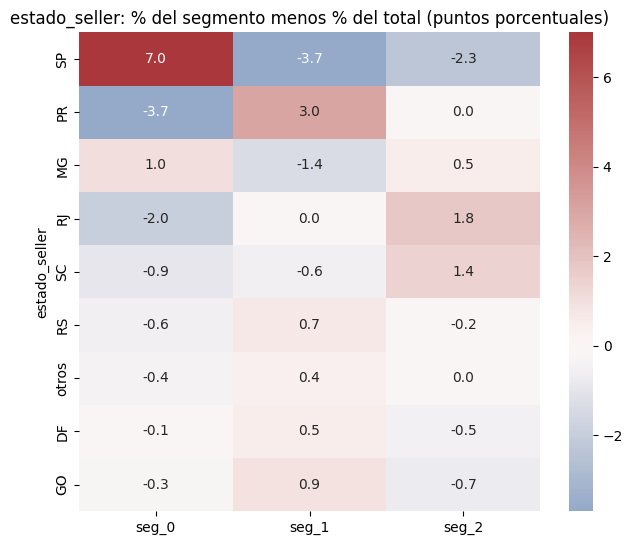


categoria_mas_pedidos: 17 valores distintos
  V de Cramér (todas las categorías): 0.08
  V de Cramér (top 8 + otros):        0.08
  p-valor chi-cuadrado (todas):       0.068
                       seg_0  seg_1  seg_2  total
categoria_mas_pedidos                            
otros                   40.3   45.1   44.8   43.6
esporte                  9.5    9.2   14.7   11.2
beleza                   9.8   11.7    9.4   10.4
moveis                   9.8    9.5    8.6    9.3
utilidades               7.2   10.6    6.5    8.2
informatica              9.8    3.9    6.5    6.6
cama                     7.9    4.2    5.3    5.7
brinquedos               5.6    5.8    4.1    5.2


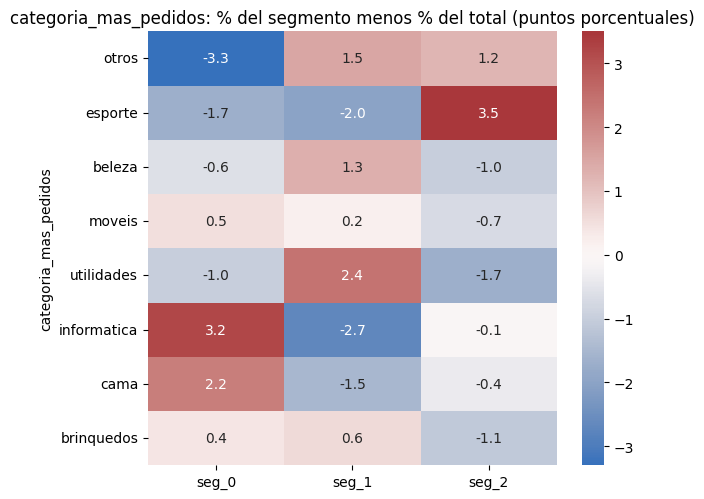

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.metrics import silhouette_score, silhouette_samples

COL_ESTADO = "estado_seller"
COL_CATEGORIA = "categoria_mas_pedidos"

seg = df_cluster_sellers["segmento"].to_numpy().astype(int)       # por posición, no por índice

# 1. Silueta por segmento
print("Silueta global:", round(silhouette_score(X, seg), 3))       # debe dar 0.198
calidad = (pd.DataFrame({"segmento": seg, "silueta": silhouette_samples(X, seg)})
             .groupby("segmento")["silueta"]
             .agg(vendedores="size", silueta_media="mean",
                  pct_negativa=lambda v: 100 * (v < 0).mean()).round(3))
calidad["pct_vendedores"] = (100 * calidad["vendedores"] / len(seg)).round(1)
print(calidad)

# 2. Estado y categoría por segmento
def agrupar_top(s, n=8):
    top = s.value_counts().head(n).index
    return s.where(s.isin(top), "otros")

def cramer_v(a, b):
    """V de Cramér con corrección de sesgo (importa con muchas categorías y pocos vendedores)."""
    t = pd.crosstab(np.asarray(a), np.asarray(b))
    chi2 = chi2_contingency(t, correction=False)[0]
    n = t.values.sum()
    r, k = t.shape
    phi2c = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2c / max(min(kc - 1, rc - 1), 1e-9)))

tablas = {}
for col in (COL_ESTADO, COL_CATEGORIA):
    s = df_cluster_sellers[col].fillna("sin dato").astype(str)
    g = agrupar_top(s)

    pct = pd.crosstab(g.to_numpy(), seg, normalize="columns").mul(100)
    pct.columns = [f"seg_{c}" for c in pct.columns]
    pct.index.name = col
    pct["total"] = g.value_counts(normalize=True).mul(100).reindex(pct.index).astype("float64")
    pct = pct.astype("float64").sort_values("total", ascending=False).round(1)

    dif = (pct.drop(columns="total").sub(pct["total"], axis=0)
              .astype("float64").round(1))
    tablas[col] = {"pct": pct, "dif": dif}

    p_valor = chi2_contingency(pd.crosstab(s.to_numpy(), seg))[1]
    print(f"\n{col}: {s.nunique()} valores distintos")
    print(f"  V de Cramér (todas las categorías): {cramer_v(s, seg):.2f}")
    print(f"  V de Cramér (top 8 + otros):        {cramer_v(g, seg):.2f}")
    print(f"  p-valor chi-cuadrado (todas):       {p_valor:.3f}")
    print(pct)

    plt.figure(figsize=(6.5, 0.45 * len(dif) + 1.5))
    sns.heatmap(dif, annot=True, fmt=".1f", cmap="vlag", center=0)
    plt.title(f"{col}: % del segmento menos % del total (puntos porcentuales)")
    plt.tight_layout()
    plt.show()

In [ ]:
print("X:", type(X), getattr(X, "shape", None))
print("filas de la tabla:", len(df_cluster_sellers))
print(df_cluster_sellers["segmento"].dtype, sorted(df_cluster_sellers["segmento"].unique()))
print([c for c in df_cluster_sellers.columns if "estado" in c.lower() or "categ" in c.lower()])
print(df_cluster_sellers[[c for c in df_cluster_sellers.columns
                          if "estado" in c.lower() or "categ" in c.lower()]].dtypes)

X: <class 'numpy.ndarray'> (1003, 11)
filas de la tabla: 1003
int32 [np.int32(0), np.int32(1), np.int32(2)]
['estado_seller', 'pedidos_mismo_estado_mediana', 'pedidos_mismo_estado', 'estados_cliente_diferentes', 'categorias_diferentes', 'categoria_mas_pedidos', 'pedidos_categoria_principal', 'tasa_pedidos_mismo_estado']
estado_seller                    object
pedidos_mismo_estado_mediana    float64
pedidos_mismo_estado              int64
estados_cliente_diferentes        int64
categorias_diferentes             int64
categoria_mas_pedidos            object
pedidos_categoria_principal     float64
tasa_pedidos_mismo_estado       float64
dtype: object


In [ ]:

from google.colab import files
df_cluster_sellers.to_csv(
    "vendedores_segmentacion.csv",
    index=False,
    encoding="utf-8"
)

files.download("vendedores_segmentacion.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df_cluster_sellers.columns

Index(['seller_id', 'estado_seller', 'cantidad_pedidos', 'n_items_vendidos',
       'monto_mediana', 'flete_mediana', 'pedidos_retrasados_mediana',
       'pedidos_adelantados_mediana', 'pedidos_mismo_estado_mediana',
       'dias_entrega_mediana', 'pedidos_retrasados', 'pedidos_adelantados',
       'pedidos_mismo_estado', 'dias_retraso_mediana',
       'estados_cliente_diferentes', 'categorias_diferentes',
       'categoria_mas_pedidos', 'pedidos_categoria_principal',
       'tasa_pedidos_retrasados', 'tasa_pedidos_adelantados',
       'tasa_pedidos_mismo_estado', 'flete_relativo', 'tasa_retraso_dias',
       'segmento', 'pc1', 'pc2', 'segmento_nombre'],
      dtype='object')

In [ ]:
import json

silueta = {
    str(int(row["k"])): float(row["silueta"])
    for _, row in resultados.iterrows()
}

with open("silueta.json", "w", encoding="utf-8") as archivo:
    json.dump(silueta, archivo, indent=4, ensure_ascii=False)

files.download("silueta.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Escogí realizar la segmentación porque, después de desarrollar el modelo predictivo de reseñas, identifiqué algunas hipótesis que consideré importante explorar. Una de las variables más relevantes del modelo estaba relacionada con la cantidad de ítems por pedido. Asimismo, al analizar la tasa de malas reseñas, observé que esta aumentaba a medida que se incrementaba la cantidad de ítems y cuando los pedidos involucraban a múltiples vendedores.

Para la segmentación, seleccioné **tres clústeres**. Esta decisión se tomó a pesar de que los valores del coeficiente de silueta eran bajos, lo que sugiere que los grupos no presentan límites claramente definidos o no están bien separados entre sí. Sin embargo, consideré que los clústeres eran funcionales para el negocio y podían aportar información útil para la toma de decisiones.

Además, realicé diferentes iteraciones incorporando otras variables; sin embargo, muchas de ellas aumentaban principalmente la dimensionalidad del conjunto de datos y generaban mejoras mínimas en el coeficiente de silueta. Para \(k = 3\), este indicador alcanzó un valor de **0.198**. En general, varias de las variables evaluadas presentaban una alta correlación entre sí, por lo que su incorporación no aportaba una mejora significativa a la separación de los grupos.

En cuanto a las variables categóricas, su incorporación mediante la codificación *one-hot encoding* generaba variables dummy adicionales, incrementando la dimensionalidad del conjunto de datos sin mejorar de forma significativa la calidad de la segmentación. En algunos casos, el coeficiente de silueta se mantenía estable o incluso disminuía.
Se identificaron 3 clúster funcionales y estrategicos para el negocio:
**El segmento 0,** alto volumen y amplia cobertura (305; 30.4%), vende unos 109 pedidos y llega a 16 estados de cliente, con montos algo menores al promedio; su puntualidad es promedio, y si acumula más pedidos retrasados en cifras absolutas es por su volumen.
**El segmento 1**, entrega puntual (359; 35.8%), tiene los mejores indicadores de entrega (la mediana de pedidos retrasados y de días de retraso es 0) con volumen y cobertura menores.
**El segmento 2**, ticket alto con retrasos (339; 33.8%), concentra los retrasos más frecuentes y prolongados (tasa de pedidos retrasados de 0.10 y 10 días de retraso mediano) y las entregas más lentas (12 días), con los montos y fletes más altos.

## Parte 4 · Deep learning: sentimiento de los comentarios

Clasifiquen una muestra de comentarios con un modelo preentrenado de Hugging Face que entienda portugués y compárenlo con las estrellas. Activen la GPU de Colab para que sea rápido.

In [ ]:
!pip install -q transformers

In [ ]:
!pip uninstall -q -y torchao

In [ ]:
import torch
#Uso de GPU
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


GPU disponible: True
GPU: Tesla T4


In [ ]:
import gc
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from transformers import pipeline, VideoMAEImageProcessor, VideoMAEForVideoClassification
from diffusers import AutoPipelineForText2Image, DiffusionPipeline
from PIL import Image
from IPython.display import Audio, Image as IPImage
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
DISPOSITIVO = 0 if torch.cuda.is_available() else -1
print("GPU disponible:", torch.cuda.is_available())

GPU disponible: True


In [ ]:
!pip -q install transformers pysentimiento scikit-learn


In [ ]:
review = text("""
WITH resenas AS (
    SELECT
        *,
        CASE
            WHEN review_score <= 2 THEN 1
            ELSE 0
        END AS mala_resena
    FROM final.order_reviews
),
muestra AS (
    SELECT
        *,
        ROW_NUMBER() OVER (
            PARTITION BY mala_resena
            ORDER BY RANDOM()
        ) AS rn,
        COUNT(*) OVER (
            PARTITION BY mala_resena
        ) AS total_clase
    FROM resenas
)
SELECT *
FROM muestra
WHERE rn <= CEIL(total_clase * 0.10)
""")

with motor.connect() as connection:
    resenas = pd.read_sql_query(review, connection)

resenas.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,mala_resena,rn,total_clase
0,d9a5d41bc78d0f565a7b8ac13585e9a9,298fcdf1f73eb413e4d26d01b25bc1cd,5,10,Muito bom!!\r\n,2018-05-15,2018-05-15 22:41:43,0,1,67807
1,7e36c5a5c2ce27e15baec1db5d8c1c40,ec31537c89ffa5a4bf45b611c840708e,5,None,Entregue no prazo e a embalagem estava um capricho. Obrigado,2017-07-22,2017-07-23 12:14:36,0,2,67807
2,e1f87d996b7a7d6634b9b5b39dd2ce31,84cad53638357a9971c4485adad123e8,4,None,None,2018-02-03,2018-02-04 09:57:52,0,3,67807
3,b61b7e7007894c6c24fb32cb0b7cad61,747aab082292790602a7f64196ca8e0f,5,None,None,2017-06-22,2017-06-23 12:18:08,0,4,67807
4,de23c38fb03573b2fd75e8099d50fa06,0136390286be8a34efdc801ed150568f,5,None,Recomendo,2017-07-25,2017-07-25 15:27:14,0,5,67807


In [ ]:
resenas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8031 entries, 0 to 8030
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   review_id                8031 non-null   object        
 1   order_id                 8031 non-null   object        
 2   review_score             8031 non-null   int64         
 3   review_comment_title     436 non-null    object        
 4   review_comment_message   3377 non-null   object        
 5   review_creation_date     8031 non-null   datetime64[ns]
 6   review_answer_timestamp  8031 non-null   datetime64[ns]
 7   mala_resena              8031 non-null   int64         
 8   rn                       8031 non-null   int64         
 9   total_clase              8031 non-null   int64         
dtypes: datetime64[ns](2), int64(4), object(4)
memory usage: 627.6+ KB


In [ ]:
import torch
import pandas as pd
import numpy as np

from pysentimiento import create_analyzer

device = "cuda" if torch.cuda.is_available() else "cpu"

analyzer = create_analyzer(
    task="sentiment",
    lang="pt",
    device=device
)

print("Dispositivo utilizado:", device)

config.json:   0%|          | 0.00/952 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  540MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/562 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/799k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/22.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

Dispositivo utilizado: cuda


In [ ]:
df_sentimiento = resenas[
    ["review_comment_message", "review_score"]
].copy()

df_sentimiento = df_sentimiento.dropna(
    subset=["review_comment_message", "review_score"]
)

df_sentimiento["review_comment_message"] = (
    df_sentimiento["review_comment_message"]
    .astype(str)
    .str.strip()
)

df_sentimiento = df_sentimiento[
    df_sentimiento["review_comment_message"] != ""
].copy()

# Convertir la puntuación a numérica
df_sentimiento["review_score"] = pd.to_numeric(
    df_sentimiento["review_score"],
    errors="coerce"
)

df_sentimiento = df_sentimiento.dropna(
    subset=["review_score"]
)

print("Comentarios disponibles:", len(df_sentimiento))
df_sentimiento.head()

Comentarios disponibles: 3374


,review_comment_message,review_score
0,Muito bom!!,5
1,Entregue no prazo e a embalagem estava um capricho. Obrigado,5
4,Recomendo,5
5,"Chegou antes do prazo, excelente",5
17,Vendedores otimos,5


In [ ]:
comentarios = df_sentimiento[
    "review_comment_message"
].tolist()

predicciones = []

batch_size = 32 if torch.cuda.is_available() else 8

for inicio in range(0, len(comentarios), batch_size):
    lote = comentarios[inicio:inicio + batch_size]

    resultados = analyzer.predict(lote)

    for resultado in resultados:
        sentimiento = resultado.output

        predicciones.append({
            "sentimiento_modelo": sentimiento,
            "prob_negativa": resultado.probas.get("NEG", 0),
            "prob_neutral": resultado.probas.get("NEU", 0),
            "prob_positiva": resultado.probas.get("POS", 0)
        })

df_predicciones = pd.DataFrame(predicciones)

df_sentimiento = df_sentimiento.reset_index(drop=True)

df_sentimiento = pd.concat(
    [df_sentimiento, df_predicciones],
    axis=1
)

df_sentimiento.head()

Map:   0%|          | 0/32 [00:00<?, ? examples/s]

Map:   0%|          | 0/32 [00:00<?, ? examples/s]

Map:   0%|          | 0/32 [00:00<?, ? examples/s]

Map:   0%|          | 0/32 [00:00<?, ? examples/s]

Map:   0%|          | 0/32 [00:00<?, ? examples/s]

...

Map:   0%|          | 0/32 [00:00<?, ? examples/s]

Map:   0%|          | 0/32 [00:00<?, ? examples/s]

Map:   0%|          | 0/32 [00:00<?, ? examples/s]

Map:   0%|          | 0/14 [00:00<?, ? examples/s]

,review_comment_message,review_score,sentimiento_modelo,prob_negativa,prob_neutral,prob_positiva
0,Muito bom!!,5,POS,0.001585,0.007197,0.991218
1,Entregue no prazo e a embalagem estava um capricho. Obrigado,5,POS,0.010155,0.046832,0.943013
2,Recomendo,5,POS,0.002915,0.016551,0.980533
3,"Chegou antes do prazo, excelente",5,POS,0.009241,0.026006,0.964753
4,Vendedores otimos,5,POS,0.002870,0.008932,0.988199


In [ ]:
df_sentimiento.to_csv(
    "sentimiento.csv",
    index=False,
    encoding="utf-8"
)

from google.colab import files
files.download("sentimiento.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def clasificar_estrellas(score):
    if score <= 2:
        return "NEG"
    elif score == 3:
        return "NEU"
    else:
        return "POS"

df_sentimiento["sentimiento_estrellas"] = (
    df_sentimiento["review_score"]
    .apply(clasificar_estrellas)
)

# Comparar las predicciones con las estrellas
df_sentimiento["coincide"] = (
    df_sentimiento["sentimiento_modelo"]
    == df_sentimiento["sentimiento_estrellas"]
)

display(
    df_sentimiento[
        [
            "review_comment_message",
            "review_score",
            "sentimiento_estrellas",
            "sentimiento_modelo",
            "prob_negativa",
            "prob_neutral",
            "prob_positiva",
            "coincide"
        ]
    ].head(20)
)

,review_comment_message,review_score,sentimiento_estrellas,sentimiento_modelo,prob_negativa,prob_neutral,prob_positiva,coincide
0,Muito bom!!,5,POS,POS,0.001585,0.007197,0.991218,True
1,Entregue no prazo e a embalagem estava um capricho. Obrigado,5,POS,POS,0.010155,0.046832,0.943013,True
2,Recomendo,5,POS,POS,0.002915,0.016551,0.980533,True
3,"Chegou antes do prazo, excelente",5,POS,POS,0.009241,0.026006,0.964753,True
4,Vendedores otimos,5,POS,POS,0.002870,0.008932,0.988199,True
5,excelente,5,POS,POS,0.002140,0.004971,0.992890,True
6,"Recebemos a encomenda, mas o produto não veio corretamente, pedimos o relógio todo preto e recebemos um preto/prata",3,NEU,NEU,0.268637,0.718892,0.012471,True
7,"O site é seguro, a navegação é ágil, os parceiros, confiáveis, os produtos são honestos e sempre entregam antes do p...",5,POS,NEU,0.040523,0.564840,0.394637,False
8,"recomendo, chegou rápido!",4,POS,POS,0.014549,0.240685,0.744766,True
9,amei o produto e a entrega super rápida!,5,POS,POS,0.001736,0.005909,0.992355,True


Accuracy: 64.08%
              precision    recall  f1-score   support

         NEG       0.75      0.53      0.62       933
         NEU       0.13      0.49      0.21       308
         POS       0.95      0.71      0.81      2133

    accuracy                           0.64      3374
   macro avg       0.61      0.58      0.55      3374
weighted avg       0.82      0.64      0.71      3374



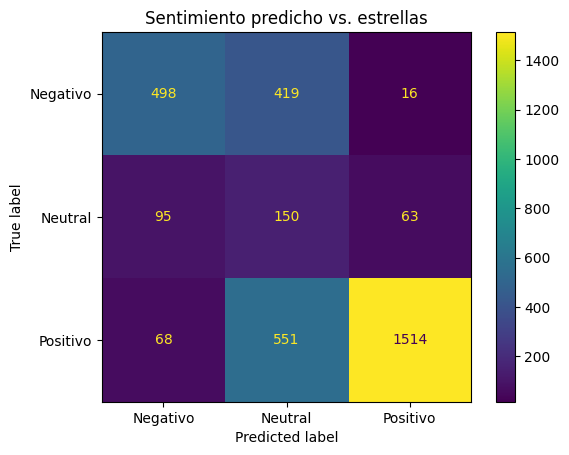

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_real = df_sentimiento["sentimiento_estrellas"]
y_pred = df_sentimiento["sentimiento_modelo"]

print(f"Accuracy: {accuracy_score(y_real, y_pred):.2%}")

print(
    classification_report(
        y_real,
        y_pred,
        labels=["NEG", "NEU", "POS"],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_real,
    y_pred,
    labels=["NEG", "NEU", "POS"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negativo", "Neutral", "Positivo"]
)

disp.plot(values_format="d")
plt.title("Sentimiento predicho vs. estrellas")
plt.show()

In [ ]:
desacuerdos = (
    df_sentimiento.loc[
        ~df_sentimiento["coincide"],
        [
            "review_comment_message",
            "review_score",
            "sentimiento_estrellas",
            "sentimiento_modelo",
            "prob_negativa",
            "prob_neutral",
            "prob_positiva"
        ]
    ]
    .sort_values("review_score")
)

display(desacuerdos.head(10))

,review_comment_message,review_score,sentimiento_estrellas,sentimiento_modelo,prob_negativa,prob_neutral,prob_positiva
3227,Produto que não passou pelo Controle de Qualidade.,1,NEG,NEU,0.061230,0.925917,0.012852
3229,Produto não entregue,1,NEG,NEU,0.241890,0.737681,0.020429
3231,Não recebi a mercadoria correta.Comprei 2(duas ) UNIDADES e SÓ CHEGOU 1(uma) unidade.,1,NEG,NEU,0.387636,0.593944,0.018420
3232,Comprei 2 e veio ao um,1,NEG,NEU,0.128067,0.826651,0.045281
3233,Fiz o pedido e decidi cancelar em seguida devido aos comentários. Recebi um e-mail da lannister confirmando o cancel...,1,NEG,NEU,0.260107,0.715033,0.024860
3238,Eu comprei 2 itens mas só chegou 1! E estou pagando por 2!,1,NEG,NEU,0.259075,0.698496,0.042429
3239,Pra mim quando coloco um produto a venda eu tenho manda o produto q está a aparecer na imagem e não manda outro dife...,1,NEG,NEU,0.410248,0.548768,0.040984
3241,O pedido realizado foi de 2 kits de pinceis e o que foi entregue foi 1 kit de pincel e 1 kit de tesoura,1,NEG,NEU,0.038863,0.931374,0.029763
3358,Oi gostaria de que se até segunda dia 19 o produto não vier vou entrar em contato com o Banco pra vc devolverem as 2...,1,NEG,NEU,0.382398,0.589402,0.028200
3357,Comprei dois telescópios e só foi entregue 1.,1,NEG,NEU,0.038547,0.936432,0.025020


In [ ]:
desacuerdos[desacuerdos["review_score"] > 2].head(10)

,review_comment_message,review_score,sentimiento_estrellas,sentimiento_modelo,prob_negativa,prob_neutral,prob_positiva
219,"São bonitas, o único problema que são muito finas. Deveria ser melhor",3,NEU,NEG,0.476105,0.109741,0.414154
201,Eu recomendo,3,NEU,POS,0.002045,0.011315,0.986639
266,"Produto mal embalado. A caixinha veio solta dentro da caixa grande do correio, aberta, com os ítens todos espalhados...",3,NEU,NEG,0.986215,0.010810,0.002975
222,Demorou muito para chegar,3,NEU,NEG,0.722949,0.257509,0.019542
938,Razoável,3,NEU,POS,0.001950,0.006821,0.991229
921,"O produto veio com uns pequenos defeitos nada demais, porém me incomodou um pouco.",3,NEU,NEG,0.941584,0.050691,0.007725
923,Faltaram os cabos e o manual,3,NEU,NEG,0.620163,0.368860,0.010977
927,"Excelente produto, correto, bem embalado mas com entrega excessivamente demorada, considerando que o mesmo é um medi...",3,NEU,POS,0.027203,0.127223,0.845574
885,Material bom entregue dentro do prazo,3,NEU,POS,0.011869,0.204385,0.783747
867,"Loja boa , porem entrega bem demorada por um produto São Paulo",3,NEU,NEG,0.795177,0.180132,0.024691


In [ ]:
df_sentimiento.to_csv(
    "resultados_analisis_sentimiento.csv",
    index=False,
    encoding="utf-8-sig"
)

from google.colab import files
files.download("resultados_analisis_sentimiento.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Preguntas

1. ¿En qué porcentaje coincide el sentimiento con las estrellas? ¿Dónde está la mayor confusión?

La muestra se seleccionó tomando proporcionalmente el 10% de cada clase, por lo que conserva aproximadamente la distribución original de las categorías.
El modelo de sentimiento obtuvo un accuracy del 64.08% sobre una muestra  equivalente a 3,374 comentarios. Esto significa que aproximadamente 6 de cada 10 comentarios fueron clasificados en la misma categoría que la asociada a sus estrellas.

Al analizar el desempeño por categoría, se observa que el modelo presenta mejores resultados al identificar comentarios positivos, con una precisión del 95% y un F1-score de 0.81. Esto indica que, cuando el modelo predice un sentimiento positivo, generalmente acierta. Sin embargo, su recall del 71% nos dice que no identifica todos los comentarios positivos existentes.

En el caso de los comentarios negativos, el modelo alcanza una precisión del 75%, un recall del 53% y un F1-score de 0.62. Esto indica que logra identificar poco más de la mitad de las reseñas clasificadas como negativas según las estrellas.
La mayor dificultad se presenta en los neutros, ya que obtiene una precisión del 13%, un recall del 49% y un F1-score de 0.21. Esto sugiere que el modelo tiene dificultades para distinguir los comentarios neutrales de los positivos y negativos. Considerar que los neutro son los que he identificado con 3 estrellas.


2. Muestren al menos 5 desacuerdos y clasifíquenlos: ¿error del modelo o del cliente?
En el caso de los comentarios asociados a calificaciones inferiores o iguales a dos estrellas que el modelo identifica como neutrales, considero que podrían representar errores de clasificación. En la muestra analizada, se observan comentarios que expresan molestias, principalmente relacionadas con productos que no corresponden a lo solicitado o con entregas fuera del plazo.

Por otro lado, al revisar los casos en los que los clientes califican su experiencia con tres estrellas, se identifican comentarios que incluyen palabras como «mal», «problema» y «tiempos de entrega», las cuales pueden llevar al modelo a clasificarlos como negativos. Considero que, en algunos de estos casos, podría existir una inconsistencia entre la calificación y el contenido del comentario, ya que la presencia de problemas durante la compra o la entrega podría reflejarse en una puntuación más baja. No obstante, una calificación intermedia también puede representar una experiencia mixta, por lo que no necesariamente debe interpretarse como un error del cliente.

En la muestra de casos en los que existe desacuerdo entre el modelo y las estrellas, las principales inconsistencias se concentran en la categoría neutral, que es precisamente aquella en la que el modelo presenta el menor desempeño. Desde mi perspectiva, los clientes con experiencias neutrales podrían tener menos incentivos para escribir comentarios, ya que no identifican aspectos positivos o negativos de su experiencia con el pedido o la entrega. Esto podría limitar la disponibilidad de ejemplos representativos de comentarios neutrales y dificultar que el modelo aprenda a identificar esta categoría correctamente.

3. ¿Qué dice el texto que las estrellas no dicen?

Las estrellas no nos dicen exactamente qué molestó al cliente ni nos da insights que podemos mejorar. Además, una calificación de 5 estrellas no siempre significa que el cliente quedó encantado; quizás solo sintió que el pedido cumplió con sus expectativas. En cambio, un comentario puede contarnos más sobre su experiencia, como qué le gustó del producto o si la entrega fue buena. Lo mismo pasa con las 3 estrellas: no sabemos si el cliente quedó satisfecho, insatisfecho o tuvo una experiencia mixta, y eso hace más difícil identificar los comentarios neutrales.

Desde mi experiencia comprando en SHEIN y Temu, las reseñas son muy importantes para decidir si compro un producto o no. Que algo tenga una valoración alta no necesariamente me da confianza; prefiero leer los comentarios de otras compradoras para saber si el color, la talla y los detalles realmente corresponden con lo que busco.

## Extra (opcional, +5) · Red neuronal contra XGBoost

Misma división por fecha y mismas variables. Muestren la curva de pérdida y expliquen el resultado.

In [ ]:
# TU CÓDIGO AQUÍ

## Parte 5 · Despliegue

- URL de la API en Render: **[https://api-resenas.onrender.com/]**
- URL de la app de Streamlit: **[https://apiresenas-m66qduubqrlomjgjsfqbcp.streamlit.app/]**

Versiones de este entorno (para su `requirements.txt` de la API):

In [ ]:
import sklearn, xgboost
print(f"pandas=={pd.__version__}\nnumpy=={np.__version__}\nscikit-learn=={sklearn.__version__}\nxgboost=={xgboost.__version__}")

pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
xgboost==3.4.1


Prueba de la API desplegada (debe devolver una probabilidad):

In [7]:
import requests
URL_API = "https://api-resenas.onrender.com"
pedido = pedidos[CONTRATO[:-1]].head(1).astype(object).where(pedidos[CONTRATO[:-1]].head(1).notna(), None).iloc[0].to_dict()
pedido = {k: (str(v) if isinstance(v, pd.Timestamp) else v) for k, v in pedido.items()}
requests.post(URL_API + "/riesgo", json=pedido, timeout=90).json()

{'detail': [{'type': 'list_type',
   'loc': ['body'],
   'msg': 'Input should be a valid list',
   'input': {'order_id': '9885fff91f7c807525f8320e5292a3db',
    'order_purchase_timestamp': '2018-01-10 14:18:40',
    'order_approved_at': '2018-01-11 02:48:39',
    'order_delivered_carrier_date': '2018-01-12 14:15:26',
    'order_delivered_customer_date': '2018-01-24 23:16:49',
    'order_estimated_delivery_date': '2018-01-31 00:00:00',
    'estado_cliente': 'SP',
    'n_items': 1,
    'n_vendedores': 1,
    'precio_total': 126.99,
    'flete_total': 29.68,
    'peso_total_g': 6150.0,
    'fotos_promedio': 3.0,
    'categoria': 'beleza_saude',
    'estado_vendedor': 'SP',
    'tipo_pago': 'boleto',
    'cuotas_max': 1.0}}]}

## Parte 6 · Ficha del modelo

La ficha va en `ficha_modelo.md` (también se muestra en la app). Aquí, solo el enlace o una copia.

## Uso de IA

Utlice ChatGPT y Clau--> fueron herramientas que me ayudaron a solventar errores de códigos durante mi entrenamiento, asimismo, me proporcionaron recomendaciones de funciones para la creación de algunas variables. Por otro lado me facilitaron la compresión y el desarollo de los códigos de la app de streamlit

In [3]:

def pagina_ficha():
    st.title("📋 Ficha del modelo")
    st.markdown("""
### 🎯 Qué predice
La probabilidad de que un pedido reciba una reseña de 1 o 2 estrellas, calculada **al momento de la
entrega** (no se usa nada de la reseña). Este modelo no es un pronóstico y no puede utilizarse antes
de la entrega.

### 🤖 Modelo
XGBoost dentro de un pipeline de scikit-learn, con las transformaciones de `preparacion.py`. El modelo
final se entrenó con todos los pedidos disponibles.

### 📅 Validación por fecha
Se entrenó con los pedidos anteriores al 28 de febrero de 2018 (56,579) y se validó con los siguientes,
hasta mayo de 2018 (20,724 pedidos; 14.8% de malas reseñas). AUC en validación: 0.794.

### 📏 Métrica
Precisión en el 10% de pedidos de mayor riesgo.
""")
    # Cifras de la validación
    ficha = pd.DataFrame({
        "Periodo": ["Validación completa", "Marzo 2018", "Abril 2018", "Mayo 2018"],
        "Azar": [0.148, 0.212, 0.118, 0.108],
        "Regla del retraso": [0.634, 0.824, 0.326, 0.335],
        "Modelo": [0.680, 0.856, 0.471, 0.428],
    }).set_index("Periodo")
    st.table(ficha.style.format("{:.3f}"))

    st.markdown("""
### 🔑 Variables que más pesan
Según la pérdida de AUC al desordenar cada variable, las que más pesan son:
- 📆 **Diferencia entre la fecha estimada y la real de entrega** (los días de retraso): pérdida
  promedio de 0.016 de AUC en los meses con menores tasas de mala reseña.
- 🛒 **Cantidad de artículos del pedido:** pérdida de 0.043.
- 🚚 **Tiempos de entrega:** pérdida de 0.017.

Al observar que la regla del retraso pierde puntos de precisión en los meses con menos retrasos, se
infiere que los días de retraso son clave para una mala reseña. Esto tiene sentido: el cliente califica
peor cuando no se cumple la fecha de entrega, y su disgusto puede ser mayor a medida que aumentan los
días de retraso.

Por otra parte, la tasa de mala reseña aumenta con la cantidad de artículos por pedido: pasa de 12.0%
con un artículo a 25.9% con dos, 30.8% con tres y 35.1% con cuatro o más. Esto está relacionado con la
cantidad de vendedores: cuantos más vendedores intervienen en un pedido, más alta puede ser la tasa de
retrasos y de mala reseña. Con un vendedor es de 13.1%, con dos sube a 48.1% (903 pedidos) y con tres
o más llega a 65.9% (solo 44 pedidos).

**Conclusión:** una explicación plausible es que los pedidos con más artículos y vendedores tienen más
oportunidades de llegar después de la fecha estimada, lo que amplía sus días de entrega total. Los
datos muestran la asociación, pero no prueban el motivo.

### ⚠️ Límites
- 📆 La fecha de entrega al cliente es obligatoria: el modelo predice al momento de la entrega.
- 📂 Los datos para la predicción por lotes deben subirse en formato JSON (valida el formato de las
  fechas antes de subirlos).
- 🎚️ El corte de «riesgo alto» (37.3%) viene de la validación y es aproximado.
- ⭐ Por sí solas, las estrellas no explican la inconformidad del cliente, por lo que no deberían
  usarse como único factor para evaluar el desempeño de un producto o de un vendedor.
- ❌ La predicción puede fallar si no se completan los campos obligatorios.

### ❓ ¿A quién puede afectar un error?
- 🏪 **Vendedores:** pueden perder comisiones o incluso asumir el costo de una mala predicción.
- 📦 **Desempeño del producto:** la predicción no considera nada de las reseñas, por lo que se
  desconoce la razón por la que un pedido se identifica como de riesgo. La causa queda a interpretación
  de quien reciba la predicción.
- 📅 **Calidad de la predicción:** el modelo desconoce los días feriados, que alargan los días de
  entrega total. También pueden fallar las fechas estimadas cuando las genera un sistema automático
  con sus propios errores.
- 🙍 **Consumidores:** una mala predicción puede etiquetarlos como clientes de alto riesgo o
  problemáticos.
- 🏢 **Empresas:** quienes confían en el modelo y concentran recursos en retener clientes pueden
  gastarlos en quienes no los necesitaban y perder a quienes sí requieren algún tratamiento.
""")